# Brain Tumor MRI Classification — Multi-Scale CNN + Graph Attention Network (GAT)

Data sources: **MRI.zip**, **archive.zip** (BRISC 2025), and **PMRAM Bangladeshi Brain Cancer — MRI Dataset** (Raw Data only). Rebuilt from `Brain_Tumor_MultiScale_GAT_v2.ipynb` with the same architecture and training procedure — only data loading changed.

**Corrected version (Nov 2026):** adds a check that only PMRAM Raw Data is loaded, fixes the k-NN edge direction in `build_graph`, fixes the McNemar alignment in Step 12, uses sample standard deviation, and adds Experiment 1 (MLP vs inductive GAT on held-out sources, 5 seeds) and Experiment 2 (near-duplicate audit). Run every cell from top to bottom in a fresh runtime.

In [1]:
!pip install umap-learn -q
!pip install torch torchvision torchaudio -q
!pip install torch_geometric -q
!pip install scikit-learn networkx imagehash grad-cam statsmodels -q

import os
for p in ["/content/torch.py", "/content/torch"]:
    if os.path.exists(p):
        print("FOUND CONFLICT:", p, "-- rename or delete this, then restart the runtime.")
!pip uninstall -y torch torchvision torchaudio -q
!pip install torch torchvision torchaudio -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# ============================================================
# SETUP
# ============================================================
import os, copy, time, json, zipfile, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import cv2
import torch
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler

from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, cohen_kappa_score,
    roc_curve, auc, precision_recall_curve
)
from statsmodels.stats.contingency_tables import mcnemar

import seaborn as sns
import networkx as nx
import imagehash

from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from torch_geometric.utils import dropout_edge

VALID_EXTS = (".jpg", ".jpeg", ".png", ".bmp")
CLASSES = ["glioma", "notumor", "meningioma", "pituitary"]

def normalize_folder_name(name):
    # strips digits/spaces/punctuation so folder names like "512Glioma" or
    # "512_Normal" still match -- the PMRAM dataset prefixes each class folder
    # with an image-resolution tag ("512Glioma", "512Normal", ...).
    return re.sub(r"[^a-z]", "", name.lower())

CLASS_ALIAS_NAMES = {
    "glioma": 0,
    "notumor": 1, "notumour": 1, "normal": 1, "healthy": 1, "nontumor": 1,
    "meningioma": 2,
    "pituitary": 3,
}
CLASS_ALIASES = {normalize_folder_name(k): v for k, v in CLASS_ALIAS_NAMES.items()}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
USE_AMP = device.type == "cuda"

SEED = 42
def set_seed(seed):
    import random
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Using device: cuda


## Step 1 — Extract all 3 datasets

Upload the three zip files through the Colab file browser (folder icon in the left sidebar → upload icon) **before** running this cell -- it looks for them already sitting in `/content/` and will not pop up an upload dialog. If a file is missing it raises a clear error telling you which one and stops, instead of prompting you.

In [4]:
def require_zip(zip_path, description):
    if not os.path.exists(zip_path):
        raise FileNotFoundError(
            f"'{zip_path}' not found. Upload {description} first: click the folder icon "
            f"in the left sidebar, then the upload icon, and select the file so it lands "
            f"directly under /content. Then re-run this cell -- no need to re-upload once "
            f"it's there for the rest of this session."
        )
    return zip_path

def extract_zip(zip_path, extract_path):
    if not os.path.exists(extract_path):
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(extract_path)
        print(f"Extracted: {extract_path}")
    else:
        print(f"Already extracted, skipping: {extract_path}")
    return extract_path

# --- 1. MRI.zip (glioma/notumor/meningioma/pituitary, pre-split Training/Testing) ---
mri_zip = require_zip("/content/MRI.zip", "MRI.zip")
extract_path_1 = extract_zip(mri_zip, "/content/MRI")
train_dir = "/content/MRI/Training"
test_dir_primary = "/content/MRI/Testing"

# --- 2. archive.zip (BRISC 2025) ---
archive_zip = require_zip("/content/archive.zip", "archive.zip")
extract_path_2 = extract_zip(archive_zip, "/content/MRI_brisc2025")

# --- 3. PMRAM Bangladeshi Brain Cancer -- MRI Dataset ---
# The outer zip contains two NESTED zips: "Raw Data.zip" and "Augmented Data.zip".
# Only Raw Data.zip is used. Augmented Data.zip holds pre-generated rotated/flipped/
# zoomed copies of the SAME underlying scans as Raw Data -- perceptual-hash dedup
# (Step 3 below) will NOT reliably catch those as duplicates, since rotating or
# flipping an image changes its hash. Pooling them in would risk a rotated copy of
# a scan landing in training while its original (or another copy) lands in test --
# real leakage, not just wasted disk space. This pipeline already does its own
# on-the-fly augmentation in Step 5, so skipping the pre-augmented copy costs nothing.
pmram_outer_zip = require_zip(
    "/content/PMRAM Bangladeshi Brain Cancer - MRI Dataset.zip",
    "the 'PMRAM Bangladeshi Brain Cancer - MRI Dataset.zip'",
)
extract_path_pmram_outer = extract_zip(pmram_outer_zip, "/content/PMRAM_outer")
pmram_raw_zip = os.path.join(
    extract_path_pmram_outer, "PMRAM Bangladeshi Brain Cancer - MRI Dataset", "Raw Data.zip"
)
extract_path_3 = extract_zip(pmram_raw_zip, "/content/PMRAM_raw")

Extracted: /content/MRI
Extracted: /content/MRI_brisc2025
Extracted: /content/PMRAM_outer
Extracted: /content/PMRAM_raw


## Step 2 — Collect every image + label from all 3 sources

In [5]:
def collect_images_from_root(root_dir):
    paths, labs = [], []
    counts = {c: 0 for c in CLASSES}
    for current_root, _, filenames in os.walk(root_dir):
        folder_key = normalize_folder_name(os.path.basename(current_root))
        if folder_key in CLASS_ALIASES:
            label = CLASS_ALIASES[folder_key]
            for file in filenames:
                if file.lower().endswith(VALID_EXTS):
                    paths.append(os.path.join(current_root, file))
                    labs.append(label)
                    counts[CLASSES[label]] += 1
    return paths, labs, counts

raw_paths, raw_labels, raw_source = [], [], []
for name, root in [
    ("ds1_primary_train", train_dir), ("ds1_primary_test", test_dir_primary),
    ("ds2_brisc2025", extract_path_2),
    ("ds3_pmram_raw", extract_path_3),
]:
    p, l, counts = collect_images_from_root(root)
    raw_paths += p; raw_labels += l; raw_source += [name] * len(p)
    print(f"{name}:", counts, "total:", len(p))
print("\nTOTAL raw image files pooled from all 3 sources:", len(raw_paths))

ds1_primary_train: {'glioma': 1400, 'notumor': 1400, 'meningioma': 1400, 'pituitary': 1400} total: 5600
ds1_primary_test: {'glioma': 400, 'notumor': 400, 'meningioma': 400, 'pituitary': 400} total: 1600
ds2_brisc2025: {'glioma': 1401, 'notumor': 1207, 'meningioma': 1635, 'pituitary': 1757} total: 6000
ds3_pmram_raw: {'glioma': 373, 'notumor': 396, 'meningioma': 363, 'pituitary': 373} total: 1505

TOTAL raw image files pooled from all 3 sources: 14705


In [6]:
# ===== DATA CHECK (added): make sure ONLY PMRAM's Raw Data is loaded =====
# PMRAM Raw Data has about 1,500 images. If this shows ~7,500, the Augmented Data
# (rotated/flipped copies of the same scans) got into the folder, which leaks copies
# of test scans into training. Fix: Runtime > Disconnect and delete runtime, re-upload
# the three zips, and run again from the top.
pmram_count = sum(1 for s in raw_source if s == "ds3_pmram_raw")
print("PMRAM images loaded:", pmram_count, "| total raw images:", len(raw_paths))
assert pmram_count < 2000, (
    f"PMRAM has {pmram_count} images -- the augmented copies are in /content/PMRAM_raw. "
    "Delete the runtime and start fresh before going on."
)
print("OK: only PMRAM Raw Data is loaded.")


PMRAM images loaded: 1505 | total raw images: 14705
OK: only PMRAM Raw Data is loaded.


## Step 3 — Deduplicate with perceptual hashing (unchanged — still critical)

In [7]:
def hash_all(paths):
    hashes, bad_idx = [], []
    for i, p in enumerate(paths):
        try:
            img = Image.open(p).convert("L")
            hashes.append(str(imagehash.phash(img, hash_size=16)))
        except Exception:
            hashes.append(None); bad_idx.append(i)
    return hashes, bad_idx

print("Hashing", len(raw_paths), "images...")
t0 = time.time()
hashes, bad_idx = hash_all(raw_paths)
print("Done in", round(time.time() - t0, 1), "s. Unreadable files skipped:", len(bad_idx))

from collections import defaultdict
hash_to_indices = defaultdict(list)
for i, h in enumerate(hashes):
    if h is not None:
        hash_to_indices[h].append(i)

print("Raw images:", len(raw_paths), "| Unique images after dedup:", len(hash_to_indices))
print("Duplicate rate: {:.1f}%".format(100 * (1 - len(hash_to_indices) / len(raw_paths))))

keep_indices = sorted(v[0] for v in hash_to_indices.values())
image_paths = np.array([raw_paths[i] for i in keep_indices])
labels = np.array([raw_labels[i] for i in keep_indices])

print("Per-class totals:", {c: int((labels == idx).sum()) for idx, c in enumerate(CLASSES)})
print("Total unique images:", len(image_paths))

Hashing 14705 images...
Done in 50.5 s. Unreadable files skipped: 0
Raw images: 14705 | Unique images after dedup: 8657
Duplicate rate: 41.1%
Per-class totals: {'glioma': 1986, 'notumor': 2804, 'meningioma': 2046, 'pituitary': 1821}
Total unique images: 8657


## Step 4 — Stratified train/val/test split on the deduplicated pool (unchanged)

In [8]:
all_indices = np.arange(len(image_paths))
split_train_idx, split_test_idx = train_test_split(all_indices, test_size=0.20, random_state=SEED, stratify=labels)
split_train_idx, split_val_idx = train_test_split(split_train_idx, test_size=0.20, random_state=SEED,
                                                    stratify=labels[split_train_idx])
print("Fine-tune train:", len(split_train_idx))
print("Fine-tune val  :", len(split_val_idx))
print("Held-out test  :", len(split_test_idx))

Fine-tune train: 5540
Fine-tune val  : 1385
Held-out test  : 1732


## Step 5 — Dataset class, transforms, CLAHE (unchanged)

In [9]:
def enhance_mri(image: Image.Image) -> Image.Image:
    img_np = np.array(image.convert("L"))
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(img_np)
    return Image.fromarray(cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB))

train_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(), transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class MRIDataset(Dataset):
    def __init__(self, paths, labels, transform, use_clahe=True):
        self.paths, self.labels, self.transform, self.use_clahe = paths, labels, transform, use_clahe
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        if self.use_clahe:
            image = enhance_mri(image)
        return self.transform(image), self.labels[idx]

NUM_WORKERS = 2
PIN_MEMORY = USE_AMP

## Step 6 — BASELINE: fine-tune ResNet50 as a plain classifier (unchanged)

In [10]:
def train_resnet_classifier(use_clahe=True, seed=SEED, epochs=12, patience=4, verbose=True):
    set_seed(seed)
    ft_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for name, param in ft_model.named_parameters():
        param.requires_grad = "layer4" in name or "fc" in name
    ft_model.fc = torch.nn.Linear(ft_model.fc.in_features, len(CLASSES))
    ft_model = ft_model.to(device)

    train_ds = MRIDataset(image_paths[split_train_idx], labels[split_train_idx], train_transform, use_clahe)
    val_ds = MRIDataset(image_paths[split_val_idx], labels[split_val_idx], eval_transform, use_clahe)
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

    criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, ft_model.parameters()), lr=1e-4, weight_decay=1e-4)
    scaler = GradScaler(enabled=USE_AMP)

    best_val_acc, counter, best_state = 0.0, 0, None
    for epoch in range(epochs):
        ft_model.train()
        running_loss = 0.0
        for images, batch_labels in train_loader:
            images, batch_labels = images.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            with autocast(enabled=USE_AMP):
                outputs = ft_model(images)
                loss = criterion(outputs, batch_labels)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            running_loss += loss.item()

        ft_model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for images, batch_labels in val_loader:
                images, batch_labels = images.to(device), batch_labels.to(device)
                with autocast(enabled=USE_AMP):
                    outputs = ft_model(images)
                preds = outputs.argmax(dim=1)
                correct += (preds == batch_labels).sum().item(); total += batch_labels.size(0)
        val_acc = correct / total
        if verbose:
            print(f"Epoch {epoch+1:02d} | Train Loss={running_loss/len(train_loader):.4f} | Val Acc={val_acc:.4f}")
        if val_acc > best_val_acc:
            best_val_acc, best_state, counter = val_acc, copy.deepcopy(ft_model.state_dict()), 0
        else:
            counter += 1
            if counter >= patience:
                if verbose: print("Early stopping.")
                break
    ft_model.load_state_dict(best_state)
    return ft_model, best_val_acc

def evaluate_resnet_on_test(ft_model, use_clahe=True):
    test_ds = MRIDataset(image_paths[split_test_idx], labels[split_test_idx], eval_transform, use_clahe)
    test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    ft_model.eval()
    all_preds, all_probs, all_true = [], [], []
    with torch.no_grad():
        for images, batch_labels in test_loader:
            images = images.to(device)
            with autocast(enabled=USE_AMP):
                outputs = ft_model(images)
                probs = F.softmax(outputs, dim=1)
            all_preds.append(probs.argmax(dim=1).cpu().numpy())
            all_probs.append(probs.cpu().numpy())
            all_true.append(batch_labels.numpy())
    return np.concatenate(all_true), np.concatenate(all_preds), np.concatenate(all_probs)

finetune_model, best_val_acc = train_resnet_classifier()
print("Best fine-tune validation accuracy:", best_val_acc)
baseline_y_true, baseline_y_pred, baseline_y_prob = evaluate_resnet_on_test(finetune_model)
baseline_test_acc = accuracy_score(baseline_y_true, baseline_y_pred)
baseline_test_f1 = f1_score(baseline_y_true, baseline_y_pred, average="weighted")
print(f"\nBASELINE (single-scale ResNet50, no graph) -- Test Accuracy: {baseline_test_acc:.4f} | F1: {baseline_test_f1:.4f}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 189MB/s]
/tmp/ipykernel_517/1990353170.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/1990353170.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


Epoch 01 | Train Loss=0.6975 | Val Acc=0.9191
Epoch 02 | Train Loss=0.4924 | Val Acc=0.9314
Epoch 03 | Train Loss=0.4513 | Val Acc=0.9509
Epoch 04 | Train Loss=0.4253 | Val Acc=0.9596
Epoch 05 | Train Loss=0.4016 | Val Acc=0.9711
Epoch 06 | Train Loss=0.3908 | Val Acc=0.9762
Epoch 07 | Train Loss=0.3918 | Val Acc=0.9567
Epoch 08 | Train Loss=0.3832 | Val Acc=0.9632
Epoch 09 | Train Loss=0.3804 | Val Acc=0.9740
Epoch 10 | Train Loss=0.3759 | Val Acc=0.9791
Epoch 11 | Train Loss=0.3721 | Val Acc=0.9755
Epoch 12 | Train Loss=0.3743 | Val Acc=0.9726
Best fine-tune validation accuracy: 0.9790613718411553


/tmp/ipykernel_517/1990353170.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):



BASELINE (single-scale ResNet50, no graph) -- Test Accuracy: 0.9734 | F1: 0.9734


## Step 7 — NEW: Multi-scale feature extraction

/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


Multi-scale feature shape: (8657, 3584) (512 + 1024 + 2048 = 3584 dims per image)


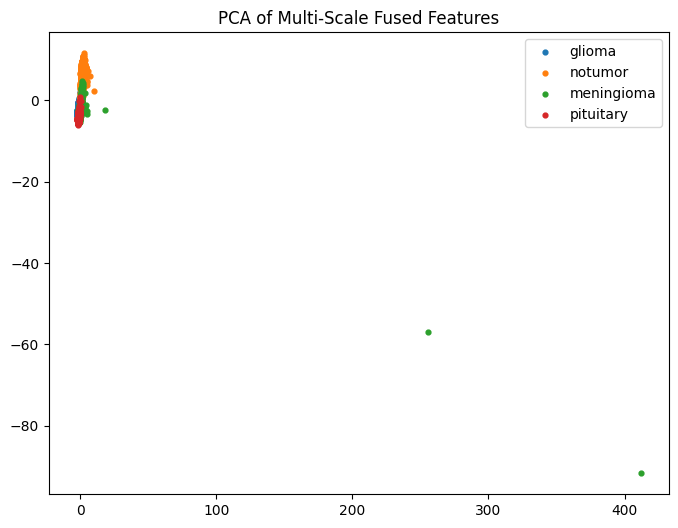

In [11]:
def extract_multiscale_features(ft_model, paths, labs, use_clahe=True):
    ft_model.eval()
    activations = {}
    def hook_fn(name):
        def hook(module, inp, out):
            activations[name] = out.detach()
        return hook
    h2 = ft_model.layer2.register_forward_hook(hook_fn("layer2"))
    h3 = ft_model.layer3.register_forward_hook(hook_fn("layer3"))
    h4 = ft_model.layer4.register_forward_hook(hook_fn("layer4"))

    gap = torch.nn.AdaptiveAvgPool2d(1)
    ds = MRIDataset(paths, labs, eval_transform, use_clahe)
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    feats = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            with autocast(enabled=USE_AMP):
                _ = ft_model(images)
                f2 = gap(activations["layer2"]).squeeze(-1).squeeze(-1)
                f3 = gap(activations["layer3"]).squeeze(-1).squeeze(-1)
                f4 = gap(activations["layer4"]).squeeze(-1).squeeze(-1)
                combined = torch.cat([f2, f3, f4], dim=1)
            feats.extend(combined.float().cpu().numpy())
    h2.remove(); h3.remove(); h4.remove()
    return np.array(feats)

features = extract_multiscale_features(finetune_model, image_paths, labels)
print("Multi-scale feature shape:", features.shape, "(512 + 1024 + 2048 = 3584 dims per image)")

pca = PCA(n_components=2)
reduced = pca.fit_transform(features)
plt.figure(figsize=(8, 6))
for i, cls in enumerate(CLASSES):
    idx = labels == i
    plt.scatter(reduced[idx, 0], reduced[idx, 1], s=12, label=cls)
plt.legend(); plt.title("PCA of Multi-Scale Fused Features"); plt.show()

## Step 8 — Build the k-NN graph: inductive vs. transductive (unchanged logic, now on multi-scale features)

In [12]:
def build_graph(features, labels, k=8, mode="transductive", train_idx=None, val_idx=None, test_idx=None):
    n = len(features)
    if mode == "transductive":
        knn = NearestNeighbors(n_neighbors=k, metric="cosine")
        knn.fit(features)
        _, indices = knn.kneighbors(features)
        edge_index = [[i, j] for i in range(n) for j in indices[i]]
    elif mode == "inductive":
        allowed_idx = np.concatenate([train_idx, val_idx])
        knn_ref = NearestNeighbors(n_neighbors=k, metric="cosine")
        knn_ref.fit(features[allowed_idx])
        edge_index = []
        _, idx_within = knn_ref.kneighbors(features[allowed_idx])
        for local_i, global_i in enumerate(allowed_idx):
            for local_j in idx_within[local_i]:
                edge_index.append([global_i, allowed_idx[local_j]])
        _, idx_test = knn_ref.kneighbors(features[test_idx])
        for local_i, global_i in enumerate(test_idx):
            for local_j in idx_test[local_i]:
                edge_index.append([global_i, allowed_idx[local_j]])
    else:
        raise ValueError("mode must be 'transductive' or 'inductive'")

    # FIX: PyG sends messages edge_index[0] -> edge_index[1], so each edge must be [neighbour, query]
    edge_index = np.ascontiguousarray(np.array(edge_index).T[::-1])
    x = torch.tensor(features, dtype=torch.float)
    y = torch.tensor(labels, dtype=torch.long)
    edge_index_t = torch.tensor(edge_index, dtype=torch.long)
    g = Data(x=x, edge_index=edge_index_t, y=y)
    num_nodes = g.num_nodes
    g.train_mask = torch.zeros(num_nodes, dtype=torch.bool)
    g.val_mask = torch.zeros(num_nodes, dtype=torch.bool)
    g.test_mask = torch.zeros(num_nodes, dtype=torch.bool)
    g.train_mask[split_train_idx] = True
    g.val_mask[split_val_idx] = True
    g.test_mask[split_test_idx] = True
    return g

graph_transductive = build_graph(features, labels, k=8, mode="transductive")
graph_inductive = build_graph(features, labels, k=8, mode="inductive",
                               train_idx=split_train_idx, val_idx=split_val_idx, test_idx=split_test_idx)
print(graph_transductive); print(graph_inductive)

Data(x=[8657, 3584], edge_index=[2, 69256], y=[8657], train_mask=[8657], val_mask=[8657], test_mask=[8657])
Data(x=[8657, 3584], edge_index=[2, 69256], y=[8657], train_mask=[8657], val_mask=[8657], test_mask=[8657])


## Step 9 — NEW: Graph Attention Network (GAT) instead of plain GCN

In [13]:
class BrainTumorGAT(torch.nn.Module):
    def __init__(self, in_channels, heads=4):
        super().__init__()
        self.conv1 = GATConv(in_channels, 512, heads=heads, dropout=0.4, concat=True)
        self.bn1 = torch.nn.BatchNorm1d(512 * heads)
        self.conv2 = GATConv(512 * heads, 256, heads=heads, dropout=0.4, concat=True)
        self.bn2 = torch.nn.BatchNorm1d(256 * heads)
        self.conv3 = GATConv(256 * heads, 128, heads=1, dropout=0.4, concat=False)
        self.bn3 = torch.nn.BatchNorm1d(128)
        self.classifier = torch.nn.Linear(128, 4)
        self.dropout = torch.nn.Dropout(0.4)

    def forward(self, data, return_embedding=False, return_attention=False):
        x, edge_index = data.x, data.edge_index
        edge_index, _ = dropout_edge(edge_index, p=0.10, training=self.training)

        x1 = F.elu(self.bn1(self.conv1(x, edge_index)))
        x1 = self.dropout(x1)
        x2 = F.elu(self.bn2(self.conv2(x1, edge_index)))
        x2 = self.dropout(x2)

        if return_attention:
            embedding, (att_edge_index, att_weights) = self.conv3(x2, edge_index, return_attention_weights=True)
        else:
            embedding = self.conv3(x2, edge_index)
        embedding = F.elu(self.bn3(embedding))
        output = self.classifier(embedding)

        if return_attention:
            return output, embedding, (att_edge_index, att_weights)
        if return_embedding:
            return output, embedding
        return output

def train_gat(graph, use_class_weights=True, epochs=100, patience=20, seed=SEED, verbose=False):
    set_seed(seed)
    g = graph.to(device)
    model = BrainTumorGAT(in_channels=g.x.shape[1]).to(device)

    if use_class_weights:
        train_labels_np = g.y[g.train_mask].cpu().numpy()
        class_counts = np.array([(train_labels_np == c).sum() for c in range(4)])
        class_weights = 1.0 / class_counts
        class_weights = class_weights / class_weights.sum() * len(class_weights)
        class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
        criterion = torch.nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
    else:
        criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

    def evaluate(mask):
        model.eval()
        with torch.no_grad():
            out = model(g)
            pred = out.argmax(dim=1)
            acc = (pred[mask] == g.y[mask]).float().mean().item()
            loss = criterion(out[mask], g.y[mask]).item()
        return acc, loss

    best_loss, counter, best_state = float("inf"), 0, None
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(g)
        loss = criterion(out[g.train_mask], g.y[g.train_mask])
        loss.backward(); optimizer.step(); scheduler.step()

        tr_acc, tr_loss = evaluate(g.train_mask)
        va_acc, va_loss = evaluate(g.val_mask)
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc); history["val_acc"].append(va_acc)

        if va_loss < best_loss:
            best_loss, best_state, counter = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            counter += 1
            if counter >= patience:
                break
        if verbose:
            print(f"Epoch {epoch+1:03d} | Train Loss={tr_loss:.4f} | Val Loss={va_loss:.4f} | Train Acc={tr_acc:.4f} | Val Acc={va_acc:.4f}")

    model.load_state_dict(best_state)
    return model, history

def evaluate_gat_on_test(model, graph):
    g = graph.to(device)
    model.eval()
    with torch.no_grad():
        logits = model(g)
        probs = F.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)
    y_true = g.y[g.test_mask].cpu().numpy()
    y_pred = preds[g.test_mask].cpu().numpy()
    y_prob = probs[g.test_mask].cpu().numpy()
    return y_true, y_pred, y_prob

gat_model, gat_history = train_gat(graph_transductive, verbose=True)
gat_y_true, gat_y_pred, gat_y_prob = evaluate_gat_on_test(gat_model, graph_transductive)
print("\nGAT (multi-scale, transductive) test accuracy:", accuracy_score(gat_y_true, gat_y_pred))

Epoch 001 | Train Loss=0.4390 | Val Loss=0.5013 | Train Acc=0.9964 | Val Acc=0.9747
Epoch 002 | Train Loss=0.4767 | Val Loss=0.5431 | Train Acc=0.9968 | Val Acc=0.9762
Epoch 003 | Train Loss=0.4811 | Val Loss=0.5456 | Train Acc=0.9969 | Val Acc=0.9762
Epoch 004 | Train Loss=0.4752 | Val Loss=0.5384 | Train Acc=0.9968 | Val Acc=0.9762
Epoch 005 | Train Loss=0.4644 | Val Loss=0.5258 | Train Acc=0.9966 | Val Acc=0.9769
Epoch 006 | Train Loss=0.4493 | Val Loss=0.5078 | Train Acc=0.9966 | Val Acc=0.9769
Epoch 007 | Train Loss=0.4341 | Val Loss=0.4890 | Train Acc=0.9966 | Val Acc=0.9769
Epoch 008 | Train Loss=0.4216 | Val Loss=0.4740 | Train Acc=0.9966 | Val Acc=0.9791
Epoch 009 | Train Loss=0.4113 | Val Loss=0.4621 | Train Acc=0.9969 | Val Acc=0.9798
Epoch 010 | Train Loss=0.4040 | Val Loss=0.4537 | Train Acc=0.9969 | Val Acc=0.9798
Epoch 011 | Train Loss=0.3993 | Val Loss=0.4481 | Train Acc=0.9969 | Val Acc=0.9791
Epoch 012 | Train Loss=0.3974 | Val Loss=0.4457 | Train Acc=0.9971 | Val Acc

## Step 10 — Ablation study (unchanged structure, now sweeping the GAT + multi-scale features on the 3-source pool)

In [18]:
# ===== Step 10 (continued): CLAHE-off and single-scale ablation rows =====
# Keeps the rows already in ablation_rows. The CLAHE-off ResNet produced NaN in half
# precision (fp16), so this one run uses full precision (fp32): slower, but stable.
_amp_saved = USE_AMP
USE_AMP = False
try:
    finetune_model_noclahe, _ = train_resnet_classifier(use_clahe=False, epochs=8, patience=3, verbose=True)
    features_noclahe = extract_multiscale_features(finetune_model_noclahe, image_paths, labels, use_clahe=False)
finally:
    USE_AMP = _amp_saved
print("NaN values in CLAHE-off features:", int(np.isnan(features_noclahe).sum()))
assert np.isfinite(features_noclahe).all(), "Still NaN in fp32 -- send this output to Claude"

g_noclahe = build_graph(features_noclahe, labels, k=8, mode="transductive")
m, _ = train_gat(g_noclahe, epochs=60, patience=12)
yt, yp, _ = evaluate_gat_on_test(m, g_noclahe)
ablation_rows.append({"config": "CLAHE=False (ResNet trained in fp32)", "test_acc": accuracy_score(yt, yp),
                       "test_f1": f1_score(yt, yp, average="weighted")})
ablation_rows.append({"config": "CLAHE=True (reference)", "test_acc": accuracy_score(gat_y_true, gat_y_pred),
                       "test_f1": f1_score(gat_y_true, gat_y_pred, average="weighted")})
print(ablation_rows[-2])

def extract_singlescale_features(ft_model, paths, labs, use_clahe=True):
    ft_model.eval()
    feature_extractor = torch.nn.Sequential(*list(ft_model.children())[:-1]).to(device)
    feature_extractor.eval()
    ds = MRIDataset(paths, labs, eval_transform, use_clahe)
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    feats = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            with autocast(enabled=USE_AMP):
                bf = feature_extractor(images)
            feats.extend(bf.squeeze(-1).squeeze(-1).float().cpu().numpy())
    return np.array(feats)

features_singlescale = extract_singlescale_features(finetune_model, image_paths, labels)
assert np.isfinite(features_singlescale).all(), "NaN in single-scale features -- send this output to Claude"
g_singlescale = build_graph(features_singlescale, labels, k=8, mode="transductive")
m, _ = train_gat(g_singlescale, epochs=60, patience=12)
yt, yp, _ = evaluate_gat_on_test(m, g_singlescale)
ablation_rows.append({"config": "multi_scale=False (layer4 only, 2048-d)", "test_acc": accuracy_score(yt, yp), "test_f1": f1_score(yt, yp, average="weighted")})
ablation_rows.append({"config": "multi_scale=True (reference, 3584-d)", "test_acc": accuracy_score(gat_y_true, gat_y_pred),
                       "test_f1": f1_score(gat_y_true, gat_y_pred, average="weighted")})

ablation_df = pd.DataFrame(ablation_rows)
print(ablation_df.to_string(index=False))

/tmp/ipykernel_517/1990353170.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/1990353170.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


Epoch 01 | Train Loss=0.6881 | Val Acc=0.9278
Epoch 02 | Train Loss=0.4812 | Val Acc=0.9422
Epoch 03 | Train Loss=0.4420 | Val Acc=0.9531
Epoch 04 | Train Loss=0.4207 | Val Acc=0.9747
Epoch 05 | Train Loss=0.3964 | Val Acc=0.9711
Epoch 06 | Train Loss=0.3865 | Val Acc=0.9747
Epoch 07 | Train Loss=0.3860 | Val Acc=0.9675
Early stopping.


/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


NaN values in CLAHE-off features: 0
{'config': 'CLAHE=False (ResNet trained in fp32)', 'test_acc': 0.9659353348729792, 'test_f1': 0.9658939797579984}


/tmp/ipykernel_517/713154940.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


                                 config  test_acc  test_f1
           graph_mode=transductive, k=4  0.973441 0.973374
           graph_mode=transductive, k=8  0.972286 0.972207
          graph_mode=transductive, k=16  0.969400 0.969292
              graph_mode=inductive, k=4  0.972864 0.972779
              graph_mode=inductive, k=8  0.974018 0.973957
             graph_mode=inductive, k=16  0.971709 0.971658
                     class_weights=True  0.972286 0.972207
                    class_weights=False  0.972286 0.972224
   CLAHE=False (ResNet trained in fp32)  0.965935 0.965894
                 CLAHE=True (reference)  0.972864 0.972794
multi_scale=False (layer4 only, 2048-d)  0.969400 0.969297
   multi_scale=True (reference, 3584-d)  0.972864 0.972794


## Step 11 — Multi-seed evaluation (unchanged structure, now GAT + multi-scale)

In [19]:
SEEDS = [42, 7, 123, 2024, 99]
multiseed_results = {"baseline": [], "gat": []}

for s in SEEDS:
    m, _ = train_resnet_classifier(seed=s, epochs=8, patience=3, verbose=False)
    yt, yp, _ = evaluate_resnet_on_test(m)
    multiseed_results["baseline"].append(accuracy_score(yt, yp))

    feats_s = extract_multiscale_features(m, image_paths, labels)
    g_s = build_graph(feats_s, labels, k=8, mode="transductive")
    gm, _ = train_gat(g_s, seed=s, epochs=60, patience=12)
    yt2, yp2, _ = evaluate_gat_on_test(gm, g_s)
    multiseed_results["gat"].append(accuracy_score(yt2, yp2))

    print(f"seed={s} | baseline_acc={multiseed_results['baseline'][-1]:.4f} | gat_acc={multiseed_results['gat'][-1]:.4f}")

for name, vals in multiseed_results.items():
    vals = np.array(vals)
    print(f"\n{name}: mean={vals.mean():.4f}  std={vals.std(ddof=1):.4f}  (n={len(vals)} seeds)")

/tmp/ipykernel_517/1990353170.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/1990353170.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


seed=42 | baseline_acc=0.9648 | gat_acc=0.9677


/tmp/ipykernel_517/1990353170.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/1990353170.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


seed=7 | baseline_acc=0.9625 | gat_acc=0.9706


/tmp/ipykernel_517/1990353170.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/1990353170.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


seed=123 | baseline_acc=0.9694 | gat_acc=0.9746


/tmp/ipykernel_517/1990353170.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/1990353170.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


seed=2024 | baseline_acc=0.9590 | gat_acc=0.9665


/tmp/ipykernel_517/1990353170.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/1990353170.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1990353170.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


seed=99 | baseline_acc=0.9706 | gat_acc=0.9729

baseline: mean=0.9652  std=0.0048  (n=5 seeds)

gat: mean=0.9704  std=0.0034  (n=5 seeds)


## Step 12 — Statistical significance: McNemar’s test (unchanged, now baseline vs. GAT)

In [20]:
# ---- Step 12 (CORRECTED): put both models' predictions in the SAME image order ----
# baseline_* arrays follow split_test_idx order (the DataLoader order);
# gat_* arrays follow sorted node order (boolean-mask indexing). They are different orders.
order = np.argsort(split_test_idx)              # split_test_idx[order] == np.sort(split_test_idx)
bl_true = baseline_y_true[order]
bl_pred = baseline_y_pred[order]
assert np.array_equal(bl_true, gat_y_true), "Predictions are still not aligned image-by-image"

baseline_correct = (bl_pred == bl_true)
gat_correct = (gat_y_pred == gat_y_true)

both_correct  = int(np.sum( baseline_correct &  gat_correct))
only_baseline = int(np.sum( baseline_correct & ~gat_correct))
only_gat      = int(np.sum(~baseline_correct &  gat_correct))
both_wrong    = int(np.sum(~baseline_correct & ~gat_correct))

table = [[both_correct, only_baseline], [only_gat, both_wrong]]
result = mcnemar(table, exact=True)
print("Test images:", len(bl_true))
print("Baseline errors:", int((~baseline_correct).sum()), "| GAT errors:", int((~gat_correct).sum()))
print("Contingency table [[both_correct, only_baseline_correct],[only_gat_correct, both_wrong]]:")
print(table)
print(f"\nMcNemar exact test: statistic={result.statistic:.4f}, p-value={result.pvalue:.4f}")
# Sanity check: models sharing a backbone should make overlapping mistakes
print("Share of the smaller error set that is common to both models: "
      f"{both_wrong / max(1, min((~baseline_correct).sum(), (~gat_correct).sum())):.2f}")


Test images: 1732
Baseline errors: 46 | GAT errors: 47
Contingency table [[both_correct, only_baseline_correct],[only_gat_correct, both_wrong]]:
[[1679, 7], [6, 40]]

McNemar exact test: statistic=6.0000, p-value=1.0000
Share of the smaller error set that is common to both models: 0.87


## Step 13 — Grad-CAM on the ResNet50 backbone (unchanged — explains the CNN’s pixel-level reasoning)

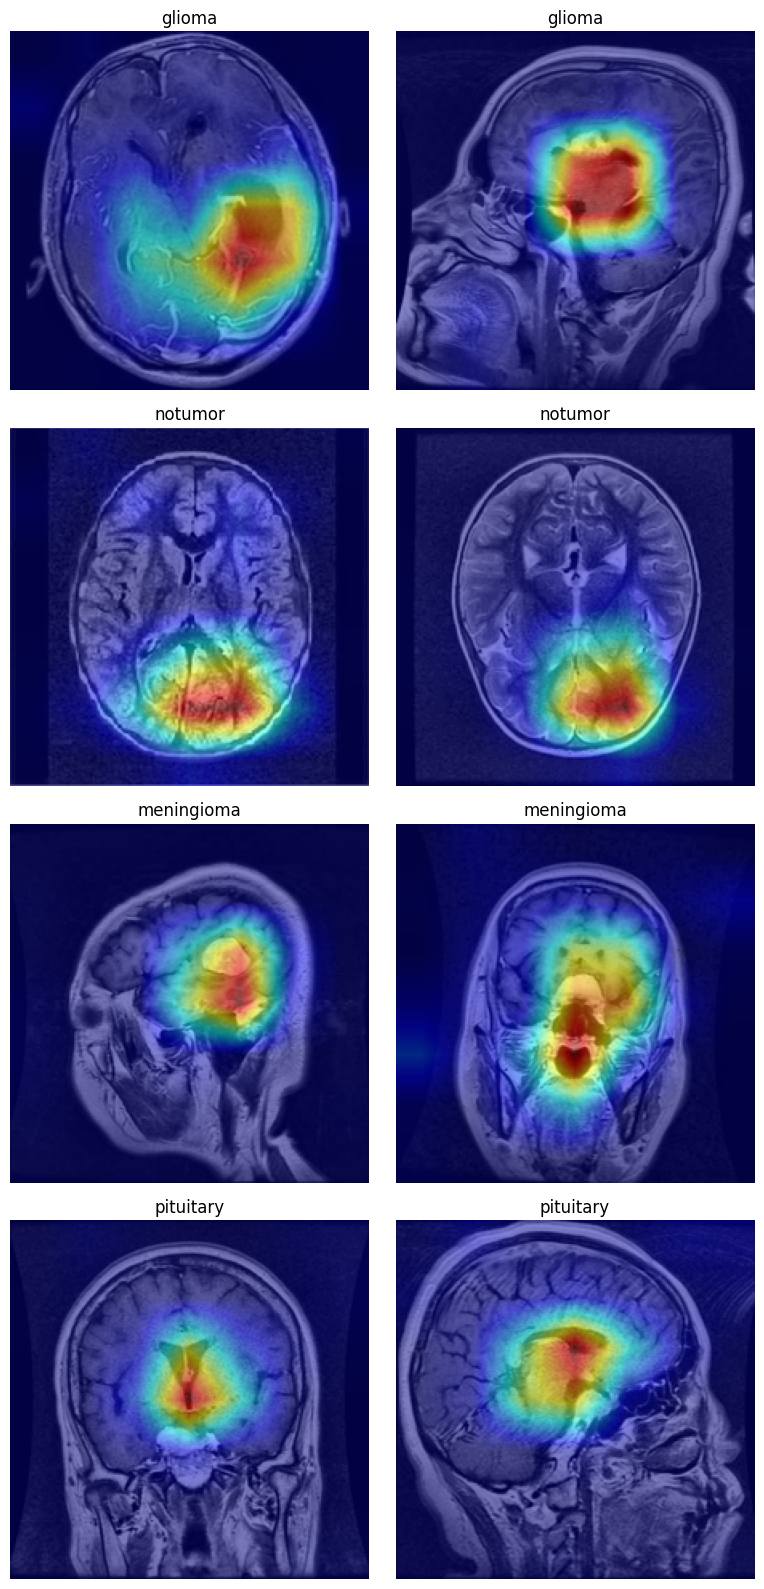

In [21]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

target_layer = [finetune_model.layer4[-1]]
cam = GradCAM(model=finetune_model, target_layers=target_layer)

def show_gradcam_examples(n_per_class=2):
    fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(4 * n_per_class, 4 * len(CLASSES)))
    for ci, cls in enumerate(CLASSES):
        idxs = np.where(labels[split_test_idx] == ci)[0][:n_per_class]
        for j, local_idx in enumerate(idxs):
            global_idx = split_test_idx[local_idx]
            img = Image.open(image_paths[global_idx]).convert("RGB")
            img_enh = enhance_mri(img)
            input_tensor = eval_transform(img_enh).unsqueeze(0).to(device)
            grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]
            rgb_img = np.array(img_enh.resize((224, 224))).astype(np.float32) / 255.0
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
            ax = axes[ci, j] if n_per_class > 1 else axes[ci]
            ax.imshow(visualization); ax.set_title(cls); ax.axis("off")
    plt.tight_layout(); plt.show()

show_gradcam_examples()

## Step 14 — NEW: Case-based explainability using GAT attention weights


=== Case-based explanation for a 'glioma' test example ===


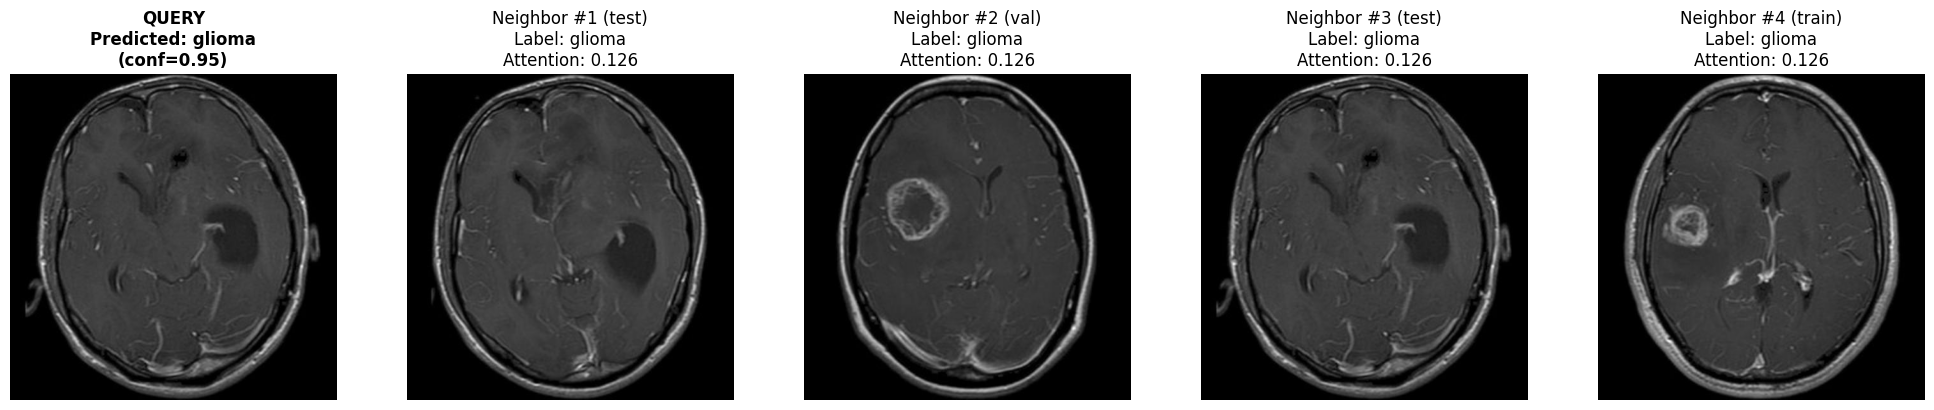


=== Case-based explanation for a 'notumor' test example ===


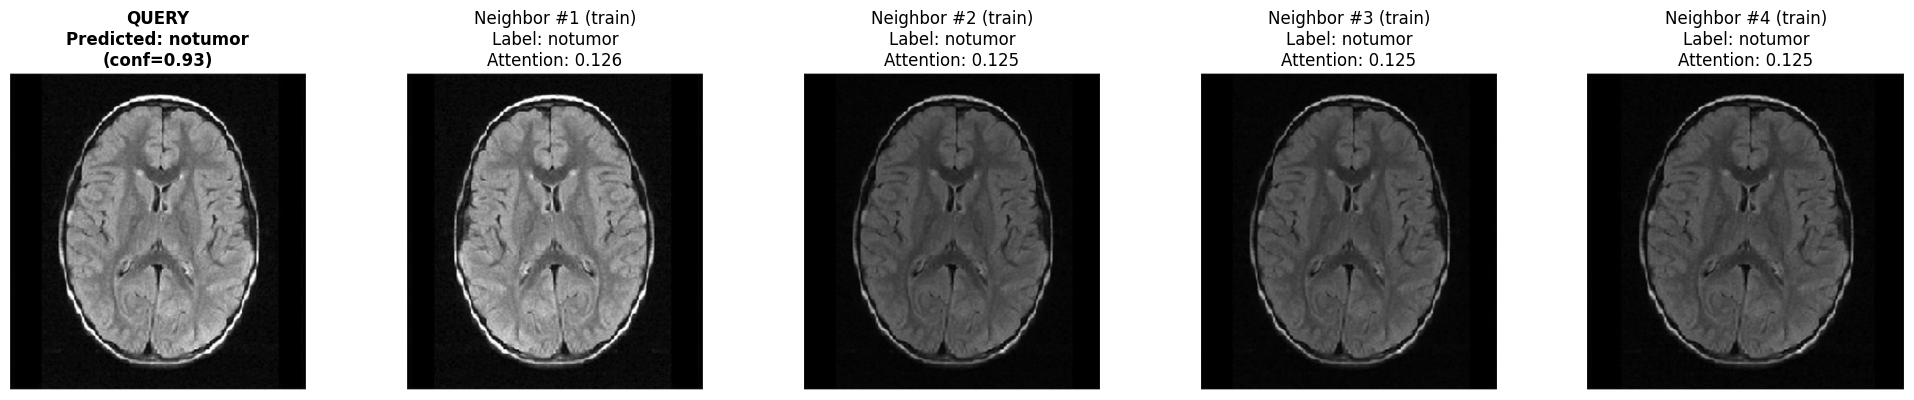


=== Case-based explanation for a 'meningioma' test example ===


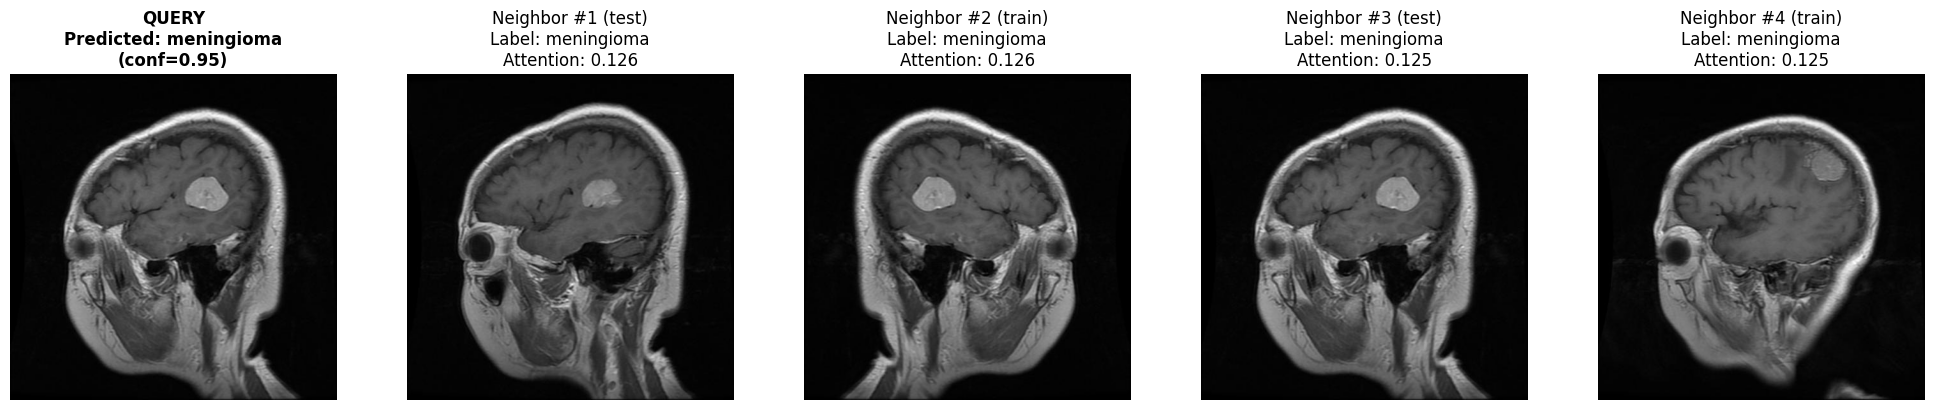


=== Case-based explanation for a 'pituitary' test example ===


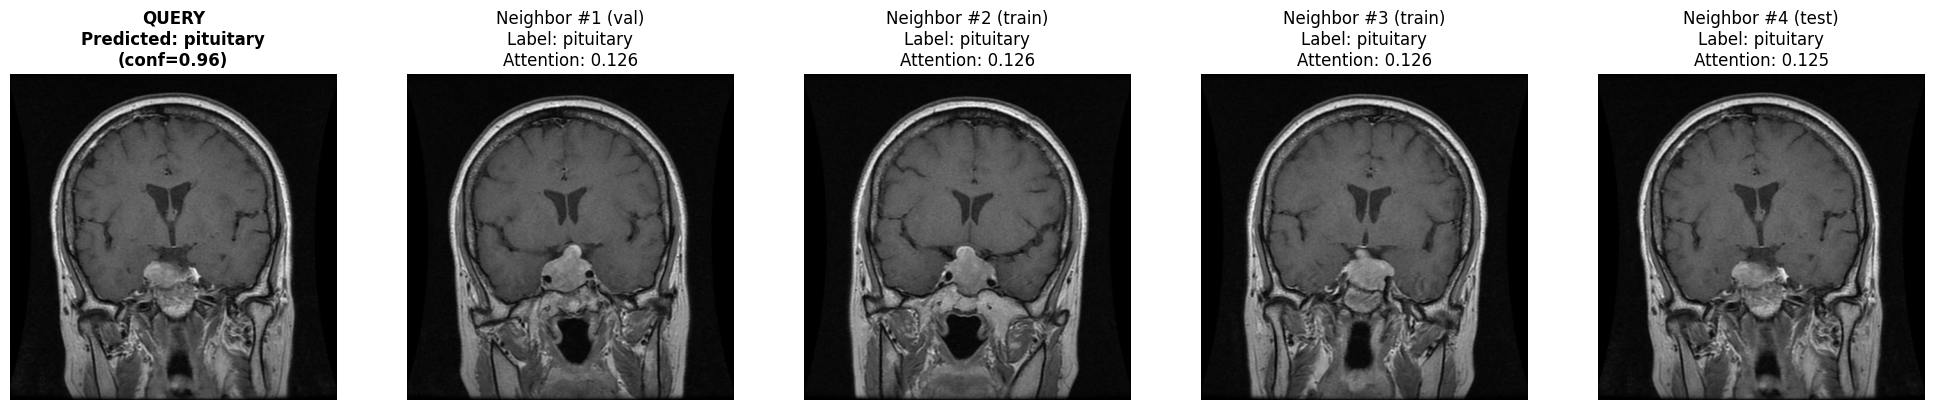

In [22]:
def explain_prediction_with_attention(model, graph, node_idx, top_k=4):
    """Returns the top-k neighbors (by learned attention weight) that most influenced
    the prediction for graph node `node_idx`, from the model's final GAT layer."""
    g = graph.to(device)
    model.eval()
    with torch.no_grad():
        logits, embedding, (att_edge_index, att_weights) = model(g, return_attention=True)

    pred = logits.argmax(dim=1)[node_idx].item()
    probs = F.softmax(logits, dim=1)[node_idx].cpu().numpy()

    att_edge_index_np = att_edge_index.cpu().numpy()
    att_weights_np = att_weights.mean(dim=1).cpu().numpy()  # average across attention heads

    # edges where this node is the TARGET (edge_index[1]) -- i.e. "who did this node attend to"
    mask = att_edge_index_np[1] == node_idx
    neighbor_nodes = att_edge_index_np[0][mask]
    neighbor_weights = att_weights_np[mask]

    order = np.argsort(-neighbor_weights)[:top_k]
    top_neighbors = neighbor_nodes[order]
    top_weights = neighbor_weights[order]
    return pred, probs, top_neighbors, top_weights

def show_case_based_explanation(model, graph, node_idx, top_k=4):
    pred, probs, top_neighbors, top_weights = explain_prediction_with_attention(model, graph, node_idx, top_k)

    fig, axes = plt.subplots(1, top_k + 1, figsize=(4 * (top_k + 1), 4))
    query_img = Image.open(image_paths[node_idx]).convert("RGB")
    axes[0].imshow(query_img, cmap="gray")
    axes[0].set_title(f"QUERY\nPredicted: {CLASSES[pred]}\n(conf={probs[pred]:.2f})", fontweight="bold")
    axes[0].axis("off")

    for i, (n_idx, w) in enumerate(zip(top_neighbors, top_weights)):
        neighbor_img = Image.open(image_paths[n_idx]).convert("RGB")
        true_label = CLASSES[labels[n_idx]]
        in_train = "train" if n_idx in split_train_idx else ("val" if n_idx in split_val_idx else "test")
        axes[i + 1].imshow(neighbor_img, cmap="gray")
        axes[i + 1].set_title(f"Neighbor #{i+1} ({in_train})\nLabel: {true_label}\nAttention: {w:.3f}")
        axes[i + 1].axis("off")
    plt.tight_layout(); plt.show()

# Show one example explanation per class from the test set
for ci, cls in enumerate(CLASSES):
    test_local_idxs = np.where(labels[split_test_idx] == ci)[0]
    if len(test_local_idxs) > 0:
        example_node = split_test_idx[test_local_idxs[0]]
        print(f"\n=== Case-based explanation for a '{cls}' test example ===")
        show_case_based_explanation(gat_model, graph_transductive, example_node, top_k=4)

## Step 15 — Model efficiency (unchanged, now reports GAT param count)

In [23]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

resnet_params = count_params(finetune_model)
gat_params = count_params(gat_model)
print(f"ResNet50 backbone parameters: {resnet_params:,}")
print(f"GAT classifier parameters:    {gat_params:,}")
print(f"Combined pipeline parameters: {resnet_params + gat_params:,}")

finetune_model.eval(); gat_model.eval()
sample_img = eval_transform(enhance_mri(Image.open(image_paths[split_test_idx[0]]).convert("RGB"))).unsqueeze(0).to(device)
with torch.no_grad():
    for _ in range(3):
        _ = finetune_model(sample_img)
    torch.cuda.synchronize() if device.type == "cuda" else None
    t0 = time.time()
    for _ in range(20):
        _ = finetune_model(sample_img)
    torch.cuda.synchronize() if device.type == "cuda" else None
    cnn_time = (time.time() - t0) / 20

print(f"\nAvg. ResNet50 forward pass time per image: {cnn_time*1000:.2f} ms")
print("The GAT stage runs once over the whole graph, not per-image -- report this honestly rather than a single per-image number.")

ResNet50 backbone parameters: 23,516,228
GAT classifier parameters:    9,584,772
Combined pipeline parameters: 33,101,000

Avg. ResNet50 forward pass time per image: 9.77 ms
The GAT stage runs once over the whole graph, not per-image -- report this honestly rather than a single per-image number.


## Step 16 — Final metrics, confusion matrix, ROC/PR curves, embeddings

In [24]:
class_names = CLASSES
accuracy = accuracy_score(gat_y_true, gat_y_pred)
precision = precision_score(gat_y_true, gat_y_pred, average="weighted")
recall = recall_score(gat_y_true, gat_y_pred, average="weighted")
f1 = f1_score(gat_y_true, gat_y_pred, average="weighted")
kappa = cohen_kappa_score(gat_y_true, gat_y_pred)

print("=" * 50)
print("FINAL RESULTS -- Multi-Scale CNN + GAT (deduplicated data, transductive, k=8)")
print("=" * 50)
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1 Score   : {f1:.4f}")
print(f"Cohen Kappa: {kappa:.4f}")
print(f"\nBaseline (single-scale ResNet50 only) Accuracy: {baseline_test_acc:.4f} | F1: {baseline_test_f1:.4f}")
print(classification_report(gat_y_true, gat_y_pred, target_names=class_names))

FINAL RESULTS -- Multi-Scale CNN + GAT (deduplicated data, transductive, k=8)
Accuracy   : 0.9729
Precision  : 0.9729
Recall     : 0.9729
F1 Score   : 0.9728
Cohen Kappa: 0.9634

Baseline (single-scale ResNet50 only) Accuracy: 0.9734 | F1: 0.9734
              precision    recall  f1-score   support

      glioma       0.97      0.94      0.96       397
     notumor       0.99      1.00      0.99       561
  meningioma       0.95      0.96      0.95       410
   pituitary       0.97      0.99      0.98       364

    accuracy                           0.97      1732
   macro avg       0.97      0.97      0.97      1732
weighted avg       0.97      0.97      0.97      1732



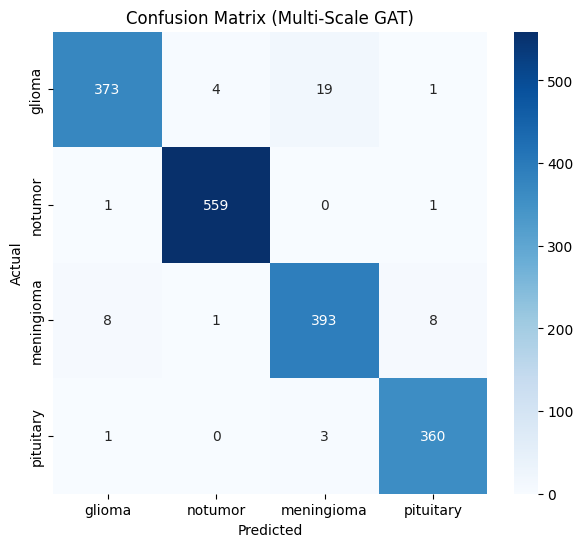

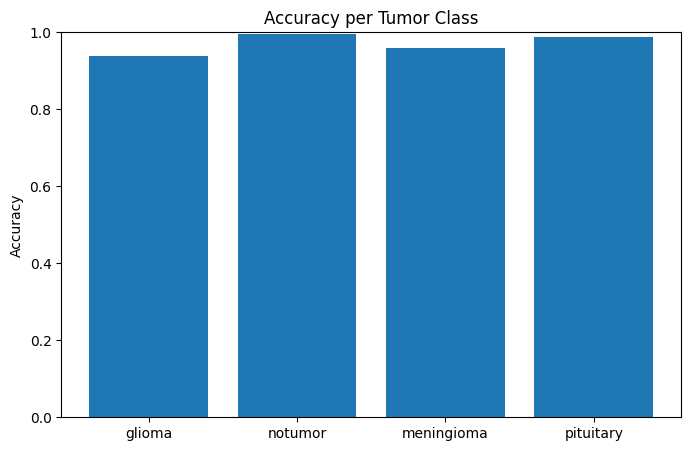

In [25]:
cm = confusion_matrix(gat_y_true, gat_y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix (Multi-Scale GAT)")
plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
plt.figure(figsize=(8, 5))
plt.bar(class_names, per_class); plt.ylim([0, 1]); plt.ylabel("Accuracy"); plt.title("Accuracy per Tumor Class")
plt.show()

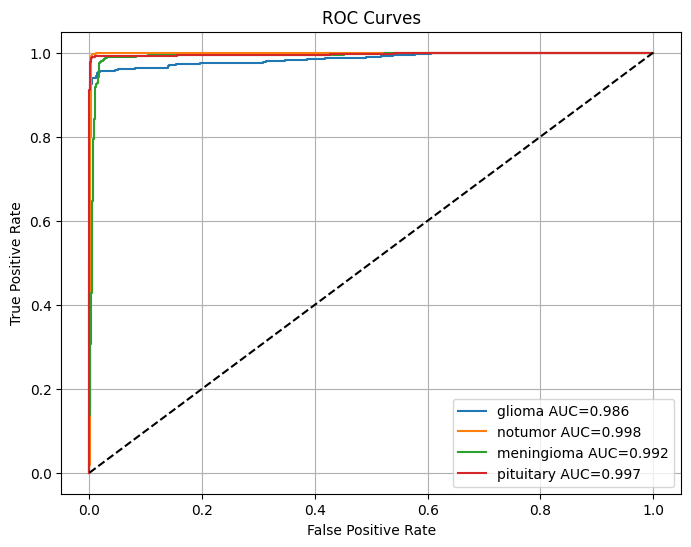

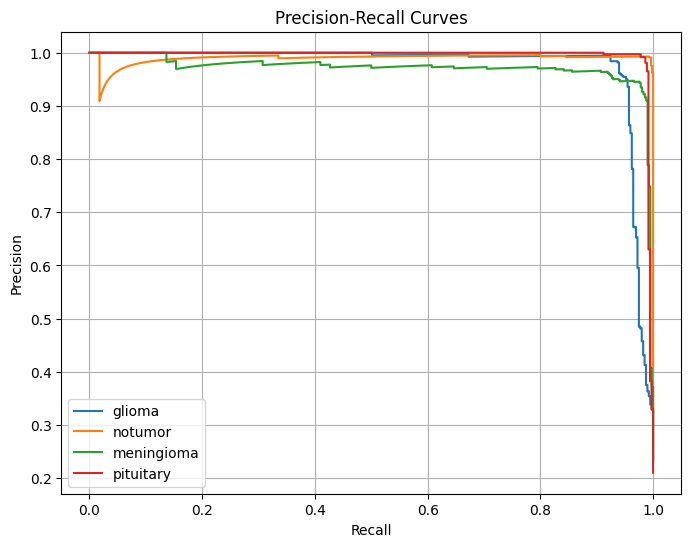

In [26]:
y_true_bin = label_binarize(gat_y_true, classes=[0, 1, 2, 3])
plt.figure(figsize=(8, 6))
for i in range(4):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], gat_y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_names[i]} AUC={roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves")
plt.legend(); plt.grid(); plt.show()

plt.figure(figsize=(8, 6))
for i in range(4):
    precision_vals, recall_vals, _ = precision_recall_curve(y_true_bin[:, i], gat_y_prob[:, i])
    plt.plot(recall_vals, precision_vals, label=class_names[i])
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves")
plt.legend(); plt.grid(); plt.show()

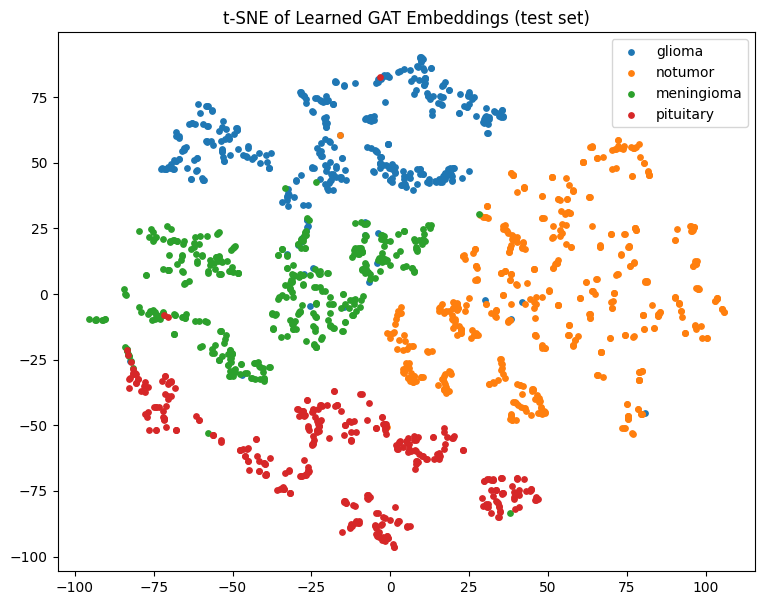

In [27]:
g = graph_transductive.to(device)
gat_model.eval()
with torch.no_grad():
    _, embeddings = gat_model(g, return_embedding=True)
embeddings = embeddings.cpu().numpy()

tsne = TSNE(n_components=2, perplexity=30, random_state=SEED)
embedding_2d = tsne.fit_transform(embeddings)

plt.figure(figsize=(9, 7))
test_mask_np = g.test_mask.cpu().numpy()
for i, cls in enumerate(class_names):
    idx = gat_y_true == i
    plt.scatter(embedding_2d[test_mask_np][idx, 0], embedding_2d[test_mask_np][idx, 1], s=15, label=cls)
plt.legend(); plt.title("t-SNE of Learned GAT Embeddings (test set)")
plt.show()

## Step 17 — Summary table for your paper’s Results section

In [28]:
def _fmt_mean_std(vals):
    vals = np.array(vals)
    return f"{vals.mean():.4f} \u00b1 {vals.std(ddof=1):.4f}"

summary_rows = []
if "multiseed_results" in globals():
    summary_rows.append({"Model": "ResNet50 baseline (single-scale, no graph)",
                          "Test Accuracy": _fmt_mean_std(multiseed_results["baseline"])})
    summary_rows.append({"Model": "Multi-Scale CNN + GAT (transductive, k=8)",
                          "Test Accuracy": _fmt_mean_std(multiseed_results["gat"])})
else:
    print("Note: multi-seed evaluation (Step 11) wasn't run -- showing single-run numbers instead.\n")
    summary_rows.append({"Model": "ResNet50 baseline (single-scale, no graph)",
                          "Test Accuracy": f"{baseline_test_acc:.4f} (single run)"})
    summary_rows.append({"Model": "Multi-Scale CNN + GAT (transductive, k=8)",
                          "Test Accuracy": f"{accuracy_score(gat_y_true, gat_y_pred):.4f} (single run)"})

summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

if "result" in globals():
    print(f"\nMcNemar p-value (baseline vs multi-scale GAT): {result.pvalue:.4f}")
else:
    print("\nMcNemar's test (Step 12) wasn't run -- skipping significance value.")

if "raw_paths" in globals() and "image_paths" in globals():
    print(f"Deduplication: {len(raw_paths)} raw images -> {len(image_paths)} unique images kept "
          f"({100*(1-len(image_paths)/len(raw_paths)):.1f}% removed as duplicates)")

if "resnet_params" in globals() and "gat_params" in globals():
    print(f"Backbone parameters: {resnet_params:,} | GAT parameters: {gat_params:,}")
else:
    print("Parameter counts (Step 15) weren't computed -- skipping.")

if "ablation_df" in globals():
    print("\nAblation study results:")
    print(ablation_df.to_string(index=False))
else:
    print("\nAblation study (Step 10) wasn't run -- skipping.")

                                     Model   Test Accuracy
ResNet50 baseline (single-scale, no graph) 0.9652 ± 0.0048
 Multi-Scale CNN + GAT (transductive, k=8) 0.9704 ± 0.0034

McNemar p-value (baseline vs multi-scale GAT): 1.0000
Deduplication: 14705 raw images -> 8657 unique images kept (41.1% removed as duplicates)
Backbone parameters: 23,516,228 | GAT parameters: 9,584,772

Ablation study results:
                                 config  test_acc  test_f1
           graph_mode=transductive, k=4  0.973441 0.973374
           graph_mode=transductive, k=8  0.972286 0.972207
          graph_mode=transductive, k=16  0.969400 0.969292
              graph_mode=inductive, k=4  0.972864 0.972779
              graph_mode=inductive, k=8  0.974018 0.973957
             graph_mode=inductive, k=16  0.971709 0.971658
                     class_weights=True  0.972286 0.972207
                    class_weights=False  0.972286 0.972224
   CLAHE=False (ResNet trained in fp32)  0.965935 0.965894
    

# New experiments (run after everything above has finished)

## Experiment 2 — How many test images have near-duplicates in training?

In [29]:
# ===== EXPERIMENT 2 (part A): near-duplicate audit -- definitions =====
# Needs from Steps 1-4: image_paths, labels, keep_indices, hashes (Step 3), raw_source (Step 2),
# split_train_idx / split_val_idx / split_test_idx (Step 4).
from PIL import ImageOps

image_source = np.array([raw_source[i].split("_")[0] for i in keep_indices])   # ds1 / ds2 / ds3
SOURCES = sorted(set(image_source))
kept_hashes = [hashes[i] for i in keep_indices]          # the 256-bit pHash strings computed in Step 3

def hash_bits(hex_hashes):
    n_bits = len(hex_hashes[0]) * 4
    return np.array([[int(b) for b in format(int(h, 16), f"0{n_bits}b")] for h in hex_hashes], dtype=np.uint8)

bits_all = hash_bits(kept_hashes)                        # (N, 256)
print("Hash length (bits):", bits_all.shape[1])

def flipped_bits(paths):
    """pHash of the horizontally / vertically flipped image (RandomHorizontalFlip is in the training
    augmentation and pHash is not flip-invariant, so a flipped copy would slip past Step 3)."""
    hs_h, hs_v = [], []
    for p in paths:
        im = Image.open(p).convert("L")
        hs_h.append(str(imagehash.phash(ImageOps.mirror(im), hash_size=16)))
        hs_v.append(str(imagehash.phash(ImageOps.flip(im), hash_size=16)))
    return hash_bits(hs_h), hash_bits(hs_v)

def nearest_hamming(q_bits, r_bits, chunk=512):
    q, r = q_bits.astype(np.float32), r_bits.astype(np.float32)
    rs = r.sum(1)
    best_d = np.empty(len(q), dtype=np.int32); best_j = np.empty(len(q), dtype=np.int64)
    for s in range(0, len(q), chunk):
        qb = q[s:s + chunk]
        d = qb.sum(1)[:, None] + rs[None, :] - 2.0 * (qb @ r.T)          # Hamming distance matrix
        j = d.argmin(1)
        best_j[s:s + chunk] = j; best_d[s:s + chunk] = np.rint(d[np.arange(len(qb)), j])
    return best_d, best_j

def near_dup_report(query_idx, ref_idx, name, thresholds=(0, 4, 8, 16, 24, 32), include_flips=True):
    """For every query image: Hamming distance to its nearest image in ref_idx (optionally also trying
    flipped versions of the query). Returns (table, best_dist, nearest_global_idx, d_orig_only)."""
    r_bits = bits_all[ref_idx]
    d_orig, j_orig = nearest_hamming(bits_all[query_idx], r_bits)
    best_d, best_j = d_orig.copy(), j_orig.copy()
    if include_flips:
        for b in flipped_bits(image_paths[query_idx]):
            d, j = nearest_hamming(b, r_bits)
            better = d < best_d
            best_d[better], best_j[better] = d[better], j[better]
    nn_global = ref_idx[best_j]
    same_label = labels[query_idx] == labels[nn_global]
    rows = []
    for t in thresholds:
        m = best_d <= t
        rows.append({"query set": name, "Hamming <=": t, "n_query": len(query_idx),
                     "orig only": int((d_orig <= t).sum()), "orig + flips": int(m.sum()),
                     "% of query": round(100 * m.mean(), 2),
                     "% same label": round(100 * same_label[m].mean(), 1) if m.any() else np.nan})
    return pd.DataFrame(rows), best_d, nn_global, d_orig

def show_pairs(query_idx, nn_global, best_d, lo, hi, n=6, seed=0):
    """Eyeball pairs with lo < distance <= hi: where do real duplicates stop and look-alikes begin?"""
    cand = np.where((best_d > lo) & (best_d <= hi))[0]
    if len(cand) == 0:
        print(f"No pairs with {lo} < d <= {hi}"); return
    pick = np.random.default_rng(seed).choice(cand, size=min(n, len(cand)), replace=False)
    fig, axes = plt.subplots(2, len(pick), figsize=(3 * len(pick), 6.4), squeeze=False)
    for c, i in enumerate(pick):
        axes[0, c].imshow(Image.open(image_paths[query_idx[i]]).convert("L"), cmap="gray")
        axes[0, c].set_title(f"query ({CLASSES[labels[query_idx[i]]]})\nd={best_d[i]}", fontsize=9)
        axes[1, c].imshow(Image.open(image_paths[nn_global[i]]).convert("L"), cmap="gray")
        axes[1, c].set_title(f"nearest train/other ({CLASSES[labels[nn_global[i]]]})", fontsize=9)
        axes[0, c].axis("off"); axes[1, c].axis("off")
    plt.tight_layout(); plt.show()


Hash length (bits): 256


                      query set  Hamming <=  n_query  orig only  orig + flips  % of query  % same label
random split: test vs train+val           0     1732          0           414       23.90          99.8
random split: test vs train+val           4     1732        202           837       48.33          99.6
random split: test vs train+val           8     1732        235           854       49.31          99.5
random split: test vs train+val          16     1732        280           877       50.64          99.5
random split: test vs train+val          24     1732        364           918       53.00          99.6
random split: test vs train+val          32     1732        550           991       57.22          99.5

           query set  Hamming <=  n_query  orig only  orig + flips  % of query  % same label
ds1 vs other sources           0     6651          0            53        0.80         100.0
ds1 vs other sources           4     6651        250           533        8.01       

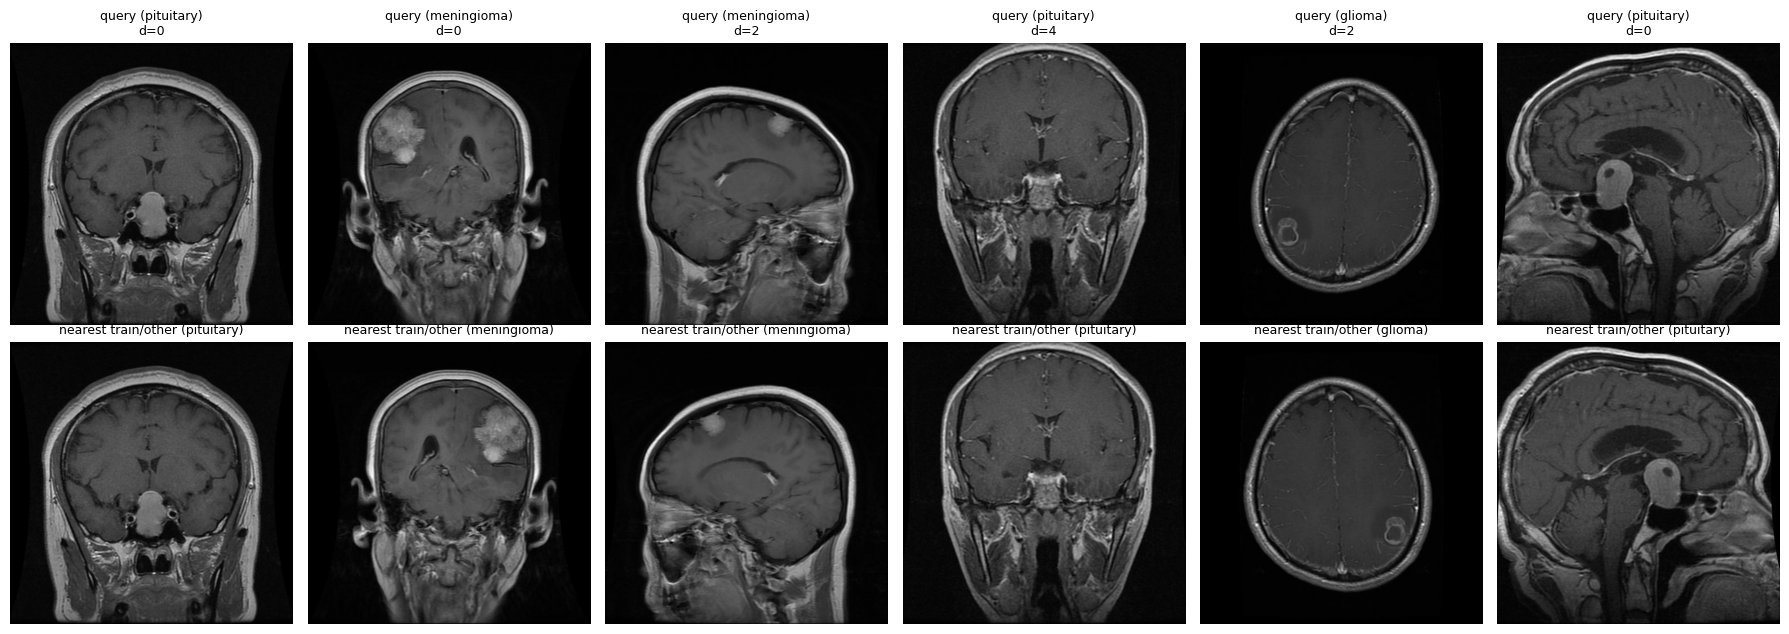

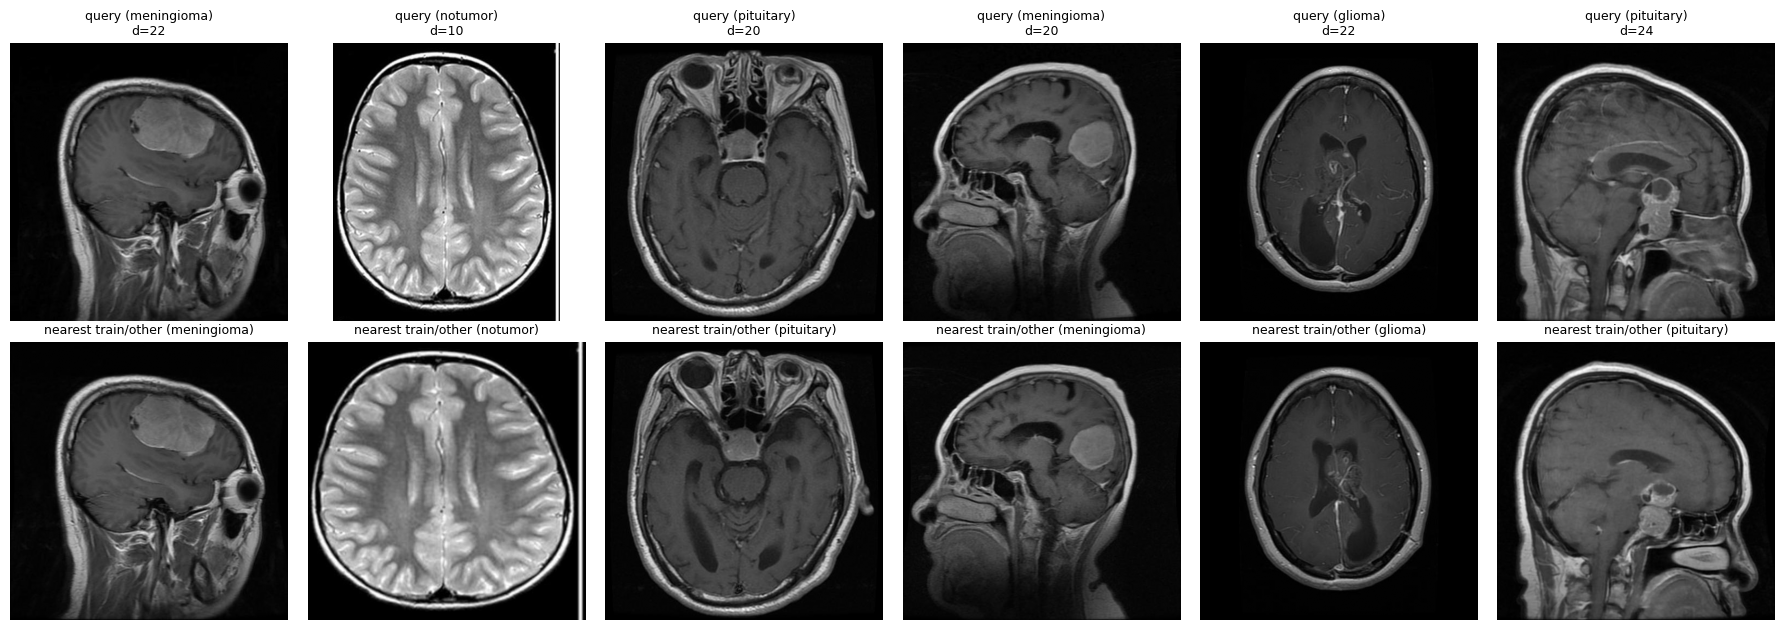

In [30]:
# ===== EXPERIMENT 2 (part B): how many test images have near-duplicates in training? =====
train_pool_idx = np.concatenate([split_train_idx, split_val_idx])

# (a) the random stratified split used for every number in the notebook
tab_a, d_a, nn_a, d_a_orig = near_dup_report(split_test_idx, train_pool_idx, "random split: test vs train+val")
print(tab_a.to_string(index=False))

# (b) leave-one-source-out: how many images of each source have a near-duplicate in the OTHER sources?
tabs, store = [tab_a], {}
for s in SOURCES:
    q = np.where(image_source == s)[0]; r = np.where(image_source != s)[0]
    t, d, nn, _ = near_dup_report(q, r, f"{s} vs other sources")
    tabs.append(t); store[s] = (q, d, nn)
    print("\n" + t.to_string(index=False))
near_dup_table = pd.concat(tabs, ignore_index=True)
near_dup_table.to_csv("/content/near_duplicate_counts.csv", index=False)

# (c) is accuracy different on test images that DO have a near-duplicate in training?
T = 16                                           # pick T after looking at show_pairs() below
flag = d_a <= T                                  # aligned with split_test_idx order
n_nodes = len(image_paths)
base_pred = np.full(n_nodes, -1); base_pred[split_test_idx] = baseline_y_pred            # baseline: split_test_idx order
gat_pred = np.full(n_nodes, -1);  gat_pred[np.sort(split_test_idx)] = gat_y_pred         # GAT: sorted-node order
for name, pred in [("ResNet50 baseline", base_pred), ("Multi-scale GAT", gat_pred)]:
    correct = (pred[split_test_idx] == labels[split_test_idx])
    print(f"{name:18s} | with near-dup (d<={T}, n={flag.sum():4d}): {correct[flag].mean() if flag.any() else float('nan'):.4f}"
          f" | without (n={(~flag).sum():4d}): {correct[~flag].mean():.4f}")

# (d) look at the pairs: exact-ish duplicates first, then the boundary zone
show_pairs(split_test_idx, nn_a, d_a, lo=-1, hi=4)
show_pairs(split_test_idx, nn_a, d_a, lo=8, hi=24)


## Experiment 1 — Held-out sources: MLP on the same features vs inductive GAT (5 seeds)

This takes a while (15 runs). It saves progress to `/content/lodo_results.csv`, so if Colab disconnects, re-run Steps 1-9 and this section and it picks up where it stopped.

In [31]:
# ===== EXPERIMENT 1 (part A): leave-one-source-out, MLP vs inductive GAT -- definitions =====
# Run AFTER Steps 1-3 and the setup cell (needs: image_paths, labels, raw_source, keep_indices,
# MRIDataset, train_transform, eval_transform, extract_multiscale_features, train_gat,
# evaluate_gat_on_test, set_seed, CLASSES, device, USE_AMP, NUM_WORKERS, PIN_MEMORY).
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score
from torch_geometric.data import Data

image_source = np.array([raw_source[i].split("_")[0] for i in keep_indices])   # ds1 / ds2 / ds3
SOURCES = sorted(set(image_source))
print("Images per source:", {str(s): int((image_source == s).sum()) for s in SOURCES})
print(pd.crosstab(image_source, labels, rownames=["source"], colnames=["class"]))   # check every source has every class


# ---- 1. backbone fine-tuned ONLY on the training sources (same recipe as Step 6) ----
def finetune_resnet_on(train_idx, val_idx, seed, epochs=8, patience=3, use_clahe=True):
    set_seed(seed)
    m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for name, p in m.named_parameters():
        p.requires_grad = "layer4" in name or "fc" in name
    m.fc = torch.nn.Linear(m.fc.in_features, len(CLASSES))
    m = m.to(device)
    tr_ds = MRIDataset(image_paths[train_idx], labels[train_idx], train_transform, use_clahe)
    va_ds = MRIDataset(image_paths[val_idx], labels[val_idx], eval_transform, use_clahe)
    tr_loader = DataLoader(tr_ds, batch_size=32, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    va_loader = DataLoader(va_ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
    scaler = GradScaler(enabled=USE_AMP)
    best_acc, counter, best_state = -1.0, 0, None
    for epoch in range(epochs):
        m.train()
        for x, y in tr_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            with autocast(enabled=USE_AMP):
                loss = criterion(m(x), y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        m.eval(); correct = total = 0
        with torch.no_grad():
            for x, y in va_loader:
                x, y = x.to(device), y.to(device)
                with autocast(enabled=USE_AMP):
                    pred = m(x).argmax(1)
                correct += (pred == y).sum().item(); total += y.size(0)
        acc = correct / total
        if acc > best_acc:
            best_acc, best_state, counter = acc, copy.deepcopy(m.state_dict()), 0
        else:
            counter += 1
            if counter >= patience:
                break
    m.load_state_dict(best_state)
    return m


@torch.no_grad()
def predict_resnet_on(m, idx, use_clahe=True):
    m.eval()
    ds = MRIDataset(image_paths[idx], labels[idx], eval_transform, use_clahe)
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    preds = []
    for x, _ in loader:
        with autocast(enabled=USE_AMP):
            preds.append(m(x.to(device)).argmax(1).cpu().numpy())
    return labels[idx], np.concatenate(preds)


# ---- 2. MLP with the SAME widths / BN / dropout / ELU as BrainTumorGAT, but no message passing ----
class FeatureMLP(torch.nn.Module):
    def __init__(self, in_channels, heads=4, p=0.4):
        super().__init__()
        self.fc1 = torch.nn.Linear(in_channels, 512 * heads); self.bn1 = torch.nn.BatchNorm1d(512 * heads)
        self.fc2 = torch.nn.Linear(512 * heads, 256 * heads); self.bn2 = torch.nn.BatchNorm1d(256 * heads)
        self.fc3 = torch.nn.Linear(256 * heads, 128);         self.bn3 = torch.nn.BatchNorm1d(128)
        self.classifier = torch.nn.Linear(128, 4)
        self.dropout = torch.nn.Dropout(p)
    def forward(self, x):
        x = self.dropout(F.elu(self.bn1(self.fc1(x))))
        x = self.dropout(F.elu(self.bn2(self.fc2(x))))
        x = F.elu(self.bn3(self.fc3(x)))
        return self.classifier(x)


def train_mlp(x_tr, y_tr, x_va, y_va, seed, epochs=60, patience=12):
    """Same optimiser / loss / schedule / early stopping (val loss) as train_gat."""
    set_seed(seed)
    x_tr, x_va = torch.tensor(x_tr, dtype=torch.float, device=device), torch.tensor(x_va, dtype=torch.float, device=device)
    y_tr, y_va = torch.tensor(y_tr, dtype=torch.long, device=device), torch.tensor(y_va, dtype=torch.long, device=device)
    model = FeatureMLP(x_tr.shape[1]).to(device)
    counts = np.bincount(y_tr.cpu().numpy(), minlength=4).astype(float)
    w = 1.0 / np.maximum(counts, 1); w = w / w.sum() * len(w)
    criterion = torch.nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float, device=device), label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)
    best_loss, counter, best_state = float("inf"), 0, None
    for epoch in range(epochs):
        model.train(); optimizer.zero_grad()
        criterion(model(x_tr), y_tr).backward(); optimizer.step(); scheduler.step()
        model.eval()
        with torch.no_grad():
            va_loss = criterion(model(x_va), y_va).item()
        if va_loss < best_loss:
            best_loss, best_state, counter = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            counter += 1
            if counter >= patience:
                break
    model.load_state_dict(best_state)
    return model


@torch.no_grad()
def predict_mlp(model, x):
    model.eval()
    return model(torch.tensor(x, dtype=torch.float, device=device)).argmax(1).cpu().numpy()


# ---- 3. strictly inductive graphs ----
# train graph : nodes = train+val images of the TRAINING sources only
# test graph  : the same nodes + held-out-source nodes, which only RECEIVE edges from their k nearest
#               training nodes. Nothing from the held-out source is used while training (incl. BatchNorm).
# corrected=True  -> edges point neighbour -> query  (PyG: messages flow edge_index[0] -> edge_index[1])
# corrected=False -> edges point query -> neighbour  (exactly how build_graph() in v3 wrote them)
def _knn(ref, query, k, query_is_ref):
    nn_ = NearestNeighbors(n_neighbors=k + int(query_is_ref), metric="cosine").fit(ref)
    _, idx = nn_.kneighbors(query)
    if query_is_ref:                              # drop the node itself, keep k real neighbours
        idx = np.stack([row[row != i][:k] for i, row in enumerate(idx)])
    return idx


def make_inductive_graphs(feats, y, tr_idx, va_idx, held_idx, k=8, corrected=True):
    allowed = np.concatenate([tr_idx, va_idx])
    A, H = len(allowed), len(held_idx)
    nn_a = _knn(feats[allowed], feats[allowed], k, True)            # (A, k) local ids
    nn_h = _knn(feats[allowed], feats[held_idx], k, False)          # (H, k) local ids into `allowed`
    q_a = np.repeat(np.arange(A), k)
    q_h = np.repeat(np.arange(H), k) + A
    def orient(nb, q):
        return np.stack([nb, q]) if corrected else np.stack([q, nb])
    e_train = orient(nn_a.reshape(-1), q_a)
    e_full = np.concatenate([e_train, orient(nn_h.reshape(-1), q_h)], axis=1)

    g_train = Data(x=torch.tensor(feats[allowed], dtype=torch.float),
                   edge_index=torch.tensor(e_train, dtype=torch.long),
                   y=torch.tensor(y[allowed], dtype=torch.long))
    g_train.train_mask = torch.zeros(A, dtype=torch.bool); g_train.train_mask[:len(tr_idx)] = True
    g_train.val_mask = torch.zeros(A, dtype=torch.bool);   g_train.val_mask[len(tr_idx):] = True
    g_train.test_mask = torch.zeros(A, dtype=torch.bool)

    g_full = Data(x=torch.tensor(np.concatenate([feats[allowed], feats[held_idx]]), dtype=torch.float),
                  edge_index=torch.tensor(e_full, dtype=torch.long),
                  y=torch.tensor(np.concatenate([y[allowed], y[held_idx]]), dtype=torch.long))
    g_full.train_mask = torch.zeros(A + H, dtype=torch.bool)
    g_full.val_mask = torch.zeros(A + H, dtype=torch.bool)
    g_full.test_mask = torch.zeros(A + H, dtype=torch.bool); g_full.test_mask[A:] = True
    # hard check of the inductive property: held-out nodes get messages only from training nodes
    dst_held = e_full[1][e_full[1] >= A] if corrected else None
    if corrected:
        assert (e_full[0][e_full[1] >= A] < A).all() and len(dst_held) == H * k
        assert (e_full[0] >= A).sum() == 0          # held-out nodes send no messages
    return g_train, g_full


def result_row(held, seed, name, yt, yp):
    return {"held_out": held, "seed": seed, "model": name, "n_test": len(yt),
            "acc": accuracy_score(yt, yp),
            "macro_f1": f1_score(yt, yp, average="macro", zero_division=0),
            "weighted_f1": f1_score(yt, yp, average="weighted", zero_division=0)}


Images per source: {'ds1': 6651, 'ds2': 1206, 'ds3': 800}
class      0     1     2     3
source                        
ds1     1778  1435  1682  1756
ds2       25  1144    37     0
ds3      183   225   327    65


In [32]:
# ===== EXPERIMENT 1 (part B): run it. 3 held-out sources x 5 seeds. Resumable. =====
RESULTS_CSV = "/content/lodo_results.csv"          # point to Drive if the runtime may disconnect
SEEDS = [42, 7, 123, 2024, 99]
K_GRAPH = 8
RUN_V3_DIRECTION = True    # also score the edge direction used by build_graph() in v3, for comparison

rows, done = [], set()
if os.path.exists(RESULTS_CSV):
    prev = pd.read_csv(RESULTS_CSV); rows = prev.to_dict("records"); done = set(zip(prev.held_out, prev.seed))
    print("Resuming; finished (source, seed) pairs:", sorted(done))

for held in SOURCES:
    held_idx = np.where(image_source == held)[0]
    pool_idx = np.where(image_source != held)[0]
    for seed in SEEDS:
        if (held, seed) in done:
            continue
        t0 = time.time()
        # the held-out source is fixed; seed changes the train/val split of the other sources + all weights
        tr_idx, va_idx = train_test_split(pool_idx, test_size=0.2, random_state=seed, stratify=labels[pool_idx])

        backbone = finetune_resnet_on(tr_idx, va_idx, seed)             # never sees the held-out source
        yt, yp = predict_resnet_on(backbone, held_idx)
        new = [result_row(held, seed, "ResNet50 head (no graph)", yt, yp)]

        feats = extract_multiscale_features(backbone, image_paths, labels)          # (N, 3584)
        del backbone; torch.cuda.empty_cache()

        allowed = np.concatenate([tr_idx, va_idx])
        mlp = train_mlp(feats[tr_idx], labels[tr_idx], feats[va_idx], labels[va_idx], seed)
        new.append(result_row(held, seed, "MLP (same features)", labels[held_idx], predict_mlp(mlp, feats[held_idx])))

        variants = [("GAT inductive (corrected edges)", True)]
        if RUN_V3_DIRECTION:
            variants.append(("GAT inductive (v3 edge direction)", False))
        for name, corrected in variants:
            g_train, g_full = make_inductive_graphs(feats, labels, tr_idx, va_idx, held_idx, K_GRAPH, corrected)
            gat, _ = train_gat(g_train, epochs=60, patience=12, seed=seed)       # trained without held-out nodes
            yt_g, yp_g, _ = evaluate_gat_on_test(gat, g_full)
            new.append(result_row(held, seed, name, yt_g, yp_g))

        rows += new
        pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)
        print(f"[{held} | seed {seed}] {time.time()-t0:.0f}s  " +
              " | ".join(f"{r['model'].split(' (')[0]}: {r['acc']:.4f}" for r in new))


/tmp/ipykernel_517/2782862785.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/2782862785.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:43: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


[ds1 | seed 42] 250s  ResNet50 head: 0.8772 | MLP: 0.8733 | GAT inductive: 0.8678 | GAT inductive: 0.8572


/tmp/ipykernel_517/2782862785.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/2782862785.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:43: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


[ds1 | seed 7] 249s  ResNet50 head: 0.8524 | MLP: 0.8254 | GAT inductive: 0.8722 | GAT inductive: 0.8260


/tmp/ipykernel_517/2782862785.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/2782862785.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:43: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


[ds1 | seed 123] 253s  ResNet50 head: 0.8626 | MLP: 0.8575 | GAT inductive: 0.8572 | GAT inductive: 0.8355


... (20 outputs left out)

/tmp/ipykernel_517/2782862785.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/2782862785.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:43: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


[ds3 | seed 2024] 631s  ResNet50 head: 0.9250 | MLP: 0.9125 | GAT inductive: 0.9287 | GAT inductive: 0.9200


/tmp/ipykernel_517/2782862785.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)
/tmp/ipykernel_517/2782862785.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:43: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/2782862785.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):
/tmp/ipykernel_517/1235336331.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):


[ds3 | seed 99] 636s  ResNet50 head: 0.9012 | MLP: 0.8925 | GAT inductive: 0.9038 | GAT inductive: 0.9100


Held-out-source ACCURACY (mean ± std over seeds)
held_out                                       ds1              ds2              ds3
model                                                                               
ResNet50 head (no graph)           0.8525 ± 0.0189  0.8831 ± 0.0474  0.9023 ± 0.0287
MLP (same features)                0.8513 ± 0.0174  0.8423 ± 0.0665  0.8988 ± 0.0210
GAT inductive (v3 edge direction)  0.8370 ± 0.0140  0.8697 ± 0.0335  0.9088 ± 0.0068
GAT inductive (corrected edges)    0.8615 ± 0.0165  0.8277 ± 0.0535  0.9133 ± 0.0126

Held-out-source MACRO-F1
held_out                                       ds1              ds2              ds3
model                                                                               
ResNet50 head (no graph)           0.8520 ± 0.0208  0.6067 ± 0.0714  0.9049 ± 0.0319
MLP (same features)                0.8519 ± 0.0183  0.5657 ± 0.0583  0.9017 ± 0.0168
GAT inductive (v3 edge direction)  0.8371 ± 0.0147  0.5127 ± 0.1147  0.9064

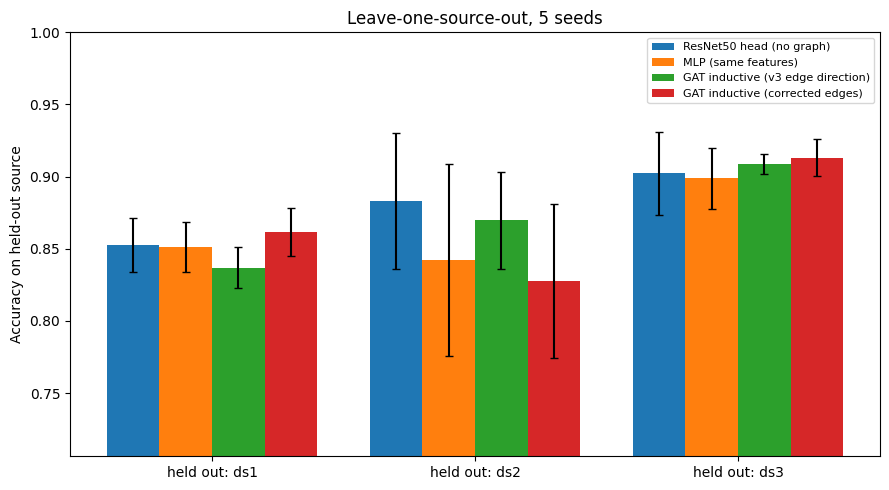

In [33]:
# ===== EXPERIMENT 1 (part C): summary table + paired comparison =====
res = pd.read_csv(RESULTS_CSV)
model_order = [m for m in ["ResNet50 head (no graph)", "MLP (same features)",
                           "GAT inductive (v3 edge direction)", "GAT inductive (corrected edges)"] if m in set(res.model)]

def fmt(x):                                     # mean +/- sample std over seeds
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}"

acc_tbl = res.pivot_table(index="model", columns="held_out", values="acc", aggfunc=fmt).loc[model_order]
f1_tbl = res.pivot_table(index="model", columns="held_out", values="macro_f1", aggfunc=fmt).loc[model_order]
print("Held-out-source ACCURACY (mean ± std over seeds)"); print(acc_tbl.to_string())
print("\nHeld-out-source MACRO-F1");                          print(f1_tbl.to_string())

# paired by (held-out source, seed): does the graph beat the MLP?
piv = res.pivot_table(index=["held_out", "seed"], columns="model", values="acc")
for g in [c for c in piv.columns if c.startswith("GAT")]:
    d = (piv[g] - piv["MLP (same features)"])
    print(f"\n{g} minus MLP: mean diff = {d.mean():+.4f}; GAT better in {(d > 0).sum()}/{len(d)} runs, "
          f"equal in {(d == 0).sum()}, worse in {(d < 0).sum()}")
    print(d.groupby(level=0).agg(["mean", "std"]).round(4).to_string())

# plot
fig, ax = plt.subplots(figsize=(9, 5))
w = 0.8 / len(model_order)
for i, m in enumerate(model_order):
    sub = res[res.model == m].groupby("held_out").acc.agg(["mean", "std"]).reindex(SOURCES)
    ax.bar(np.arange(len(SOURCES)) + i * w, sub["mean"], w, yerr=sub["std"], capsize=3, label=m)
ax.set_xticks(np.arange(len(SOURCES)) + w * (len(model_order) - 1) / 2); ax.set_xticklabels([f"held out: {s}" for s in SOURCES])
ax.set_ylim(max(0, res.acc.min() - 0.05), 1.0); ax.set_ylabel("Accuracy on held-out source"); ax.legend(fontsize=8)
ax.set_title("Leave-one-source-out, 5 seeds"); plt.tight_layout(); plt.show()


In [34]:
# ===== EXPORT: collect every number the paper needs into one file =====
# Run this as the LAST cell. Missing parts are skipped and listed under "errors".
import json, os, numpy as np, pandas as pd, torch, sklearn
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             cohen_kappa_score, roc_auc_score)

out, errors = {}, {}
def part(name, fn):
    try:
        out[name] = fn()
    except Exception as e:
        errors[name] = f"{type(e).__name__}: {e}"

def _versions():
    v = {"torch": torch.__version__, "sklearn": sklearn.__version__,
         "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}
    import torch_geometric; v["torch_geometric"] = torch_geometric.__version__
    return v
part("versions", _versions)

def _data():
    src_kept = np.array([raw_source[i] for i in keep_indices])
    return {"raw_total": len(raw_paths),
            "raw_per_source": pd.Series(raw_source).value_counts().to_dict(),
            "raw_per_source_class": pd.crosstab(np.array(raw_source), np.array(raw_labels)).rename(columns=dict(enumerate(CLASSES))).to_dict(orient="index"),
            "unique_total": len(image_paths),
            "unique_per_class": {c: int((labels == i).sum()) for i, c in enumerate(CLASSES)},
            "unique_per_source_class": pd.crosstab(src_kept, labels).rename(columns=dict(enumerate(CLASSES))).to_dict(orient="index"),
            "split_sizes": {"train": len(split_train_idx), "val": len(split_val_idx), "test": len(split_test_idx)},
            "test_per_class": {c: int((labels[split_test_idx] == i).sum()) for i, c in enumerate(CLASSES)}}
part("data", _data)

def _model_report(y_true, y_pred, y_prob):
    return {"acc": accuracy_score(y_true, y_pred),
            "kappa": cohen_kappa_score(y_true, y_pred),
            "cm_rows_true_cols_pred": confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3]).tolist(),
            "report": classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True, zero_division=0),
            "auc_per_class": {c: roc_auc_score((y_true == i).astype(int), y_prob[:, i]) for i, c in enumerate(CLASSES)}}

part("baseline_test", lambda: {"best_val_acc": best_val_acc, **_model_report(baseline_y_true, baseline_y_pred, baseline_y_prob)})
part("gat_test", lambda: _model_report(gat_y_true, gat_y_pred, gat_y_prob))

def _gat_training():
    h = gat_history
    return {"epochs_run": len(h["val_loss"]), "best_epoch_by_val_loss": int(np.argmin(h["val_loss"])) + 1, "history": h}
part("gat_training", _gat_training)

def _gat_val():
    gg = graph_transductive.to(device); gat_model.eval()
    with torch.no_grad():
        pv = gat_model(gg).argmax(1)
    vm = gg.val_mask
    yt, yp = gg.y[vm].cpu().numpy(), pv[vm].cpu().numpy()
    return {"acc": accuracy_score(yt, yp), "n": int(vm.sum()), "cm_rows_true_cols_pred": confusion_matrix(yt, yp, labels=[0, 1, 2, 3]).tolist()}
part("gat_validation", _gat_val)

part("ablation", lambda: ablation_df.to_dict("records"))
part("multiseed", lambda: {k: [float(x) for x in v] for k, v in multiseed_results.items()} | {"seeds": SEEDS if "SEEDS" in globals() else None})
part("mcnemar", lambda: {"table_[[both_correct,only_baseline],[only_gat,both_wrong]]": [[int(x) for x in r] for r in table],
                         "statistic": float(result.statistic), "p_value": float(result.pvalue)})
part("efficiency", lambda: {"resnet_params": int(resnet_params), "gat_params": int(gat_params), "resnet_ms_per_image": float(cnn_time) * 1000})

def _attention_cases():
    cases = []
    for ci, cls in enumerate(CLASSES):
        loc = np.where(labels[split_test_idx] == ci)[0]
        if len(loc) == 0: continue
        node = int(split_test_idx[loc[0]])
        pred, probs, nbrs, ws = explain_prediction_with_attention(gat_model, graph_transductive, node, top_k=4)
        cases.append({"class": cls, "node": node, "pred": CLASSES[pred], "conf": float(probs[pred]),
                      "neighbors": [{"label": CLASSES[labels[n]], "attention": float(w),
                                     "split": "train" if n in split_train_idx else ("val" if n in split_val_idx else "test")}
                                    for n, w in zip(nbrs, ws)]})
    return cases
part("attention_cases", _attention_cases)

def _exp2():
    d = {"table": near_dup_table.to_dict("records")}
    pred_b = np.full(len(image_paths), -1); pred_b[split_test_idx] = baseline_y_pred
    pred_g = np.full(len(image_paths), -1); pred_g[np.sort(split_test_idx)] = gat_y_pred
    for T in (0, 4, 8, 16, 24, 32):
        f = d_a <= T
        for name, p in (("baseline", pred_b), ("gat", pred_g)):
            c = p[split_test_idx] == labels[split_test_idx]
            d[f"acc_T{T}_{name}"] = {"with_neardup_n": int(f.sum()), "with_neardup_acc": float(c[f].mean()) if f.any() else None,
                                     "without_n": int((~f).sum()), "without_acc": float(c[~f].mean())}
    return d
part("experiment2_near_duplicates", _exp2)

part("experiment1_held_out_sources", lambda: pd.read_csv(RESULTS_CSV).to_dict("records"))

out["errors"] = errors
txt = json.dumps(out, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else (o.item() if hasattr(o, "item") else str(o)))
path = "/content/drive/MyDrive/msgat_results.json" if os.path.isdir("/content/drive/MyDrive") else "/content/msgat_results.json"
open(path, "w").write(txt)
print("Saved:", path, f"({len(txt):,} characters)")
print("Parts that could not be exported:", errors if errors else "none")

Saved: /content/msgat_results.json (37,570 characters)
Parts that could not be exported: none
